# SET 1: TRAINING ON PEFOXALIN

In [4]:
# Install required packages
!pip install xgboost -q

# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                             f1_score, confusion_matrix, classification_report,
                             make_scorer)
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

import warnings
warnings.filterwarnings('ignore')

# Set random seed for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("✓ Setup complete!")
print(f"Pandas: {pd.__version__}")
print(f"NumPy: {np.__version__}")

✓ Setup complete!
Pandas: 2.2.2
NumPy: 1.26.4


## LOADING DATASET

In [5]:
# File paths for Pefoxacin datasets (Set 1)
PEFOXACIN_FILES = {
    'Genes + K-mers': 'Downloads/salmonella_dna/398 files/genes_kmers_labels_398.csv',
    'Genes + SNPs': 'Downloads/salmonella_dna/398 files/genes_snps_labels_398.csv',
    'SNPs Only': 'Downloads/salmonella_dna/398 files/snps_only_labels_398.csv',
    'SNPs + K-mers': 'Downloads/salmonella_dna/398 files/snps_kmers_labels_398.csv'
}

# Configuration
CONFIG = {
    'n_folds': 6,
    'random_state': 42,
    'antibiotic': 'Pefoxacin',
    'label_column': 'Pefloxacin_Phenotype'  
}

print("="*70)
print(f"SET 1: {CONFIG['antibiotic']} Resistance Prediction")
print("="*70)
print(f"Number of dataset variants: {len(PEFOXACIN_FILES)}")
print(f"Cross-validation folds: {CONFIG['n_folds']}")
print("="*70)

SET 1: Pefoxacin Resistance Prediction
Number of dataset variants: 4
Cross-validation folds: 6


In [6]:
def load_data(filepath, label_column):
    """Load CSV and separate features from labels"""
    df = pd.read_csv(filepath)
    
    # Remove Genome_ID and label column to get features
    X = df.drop(columns=['Genome_ID', label_column])
    y = df[label_column]
    
    # Validate
    assert len(X) == len(y), "Mismatch in samples"
    assert y.isin([0, 1]).all(), "Labels must be 0 (susceptible) or 1 (resistant)"
    
    print(f"  ✓ Loaded: {len(X)} samples × {X.shape[1]} features")
    print(f"    Susceptible (0): {(y==0).sum()} ({(y==0).sum()/len(y)*100:.1f}%)")
    print(f"    Resistant (1): {(y==1).sum()} ({(y==1).sum()/len(y)*100:.1f}%)")
    
    return X, y


def get_models(scale_pos_weight):
    """Initialize models with class weight balancing"""
    models = {
        'Random Forest': RandomForestClassifier(
            n_estimators=100,
            max_depth=10,
            class_weight='balanced',
            random_state=CONFIG['random_state'],
            n_jobs=-1
        ),
        'Extra Trees': ExtraTreesClassifier(
            n_estimators=100,
            max_depth=10,
            class_weight='balanced',
            random_state=CONFIG['random_state'],
            n_jobs=-1
        ),
        'Gradient Boosting': GradientBoostingClassifier(
            n_estimators=100,
            max_depth=5,
            random_state=CONFIG['random_state']
        ),
        'XGBoost': XGBClassifier(
            n_estimators=100,
            max_depth=5,
            scale_pos_weight=scale_pos_weight,
            random_state=CONFIG['random_state'],
            eval_metric='logloss',
            use_label_encoder=False
        )
    }
    return models


def evaluate_model_cv(X, y, model, n_folds=6):
    """
    Perform stratified k-fold cross-validation and return metrics
    """
    skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=CONFIG['random_state'])
    
    # Define scorers
    scoring = {
        'accuracy': make_scorer(accuracy_score),
        'precision': make_scorer(precision_score, zero_division=0),
        'recall': make_scorer(recall_score, zero_division=0),
        'f1': make_scorer(f1_score, zero_division=0)
    }
    
    # Calculate metrics for each fold
    metrics = {
        'accuracy': [],
        'precision': [],
        'recall': [],
        'f1': []
    }
    
    for train_idx, val_idx in skf.split(X, y):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]
        
        # Train
        model.fit(X_train, y_train)
        
        # Predict
        y_pred = model.predict(X_val)
        
        # Calculate metrics
        metrics['accuracy'].append(accuracy_score(y_val, y_pred))
        metrics['precision'].append(precision_score(y_val, y_pred, zero_division=0))
        metrics['recall'].append(recall_score(y_val, y_pred, zero_division=0))
        metrics['f1'].append(f1_score(y_val, y_pred, zero_division=0))
    
    # Return mean metrics
    return {k: np.mean(v) for k, v in metrics.items()}


print("✓ Helper functions loaded")

✓ Helper functions loaded


## CROSS VALIDATION TRAINING

In [7]:
# Storage for results
all_results = []

print("\n" + "="*70)
print(f"TRAINING MODELS FOR SET 1: {CONFIG['antibiotic']}")
print("="*70)

for dataset_name, filepath in PEFOXACIN_FILES.items():
    print(f"\n{'='*70}")
    print(f"Dataset Variant: {dataset_name}")
    print(f"{'='*70}")
    
    # Load data
    X, y = load_data(filepath, CONFIG['label_column'])
    
    # Calculate class weight for XGBoost
    n_susceptible = (y == 0).sum()
    n_resistant = (y == 1).sum()
    scale_pos_weight = n_susceptible / n_resistant if n_resistant > 0 else 1.0
    
    print(f"  Class imbalance ratio: {scale_pos_weight:.2f}")
    
    # Get models
    models = get_models(scale_pos_weight)
    
    # Train each model
    for model_name, model in models.items():
        print(f"\n  Training: {model_name}...")
        
        # Cross-validation
        metrics = evaluate_model_cv(X, y, model, n_folds=CONFIG['n_folds'])
        
        # Store results
        all_results.append({
            'Antibiotic': CONFIG['antibiotic'],
            'Dataset': dataset_name,
            'Model': model_name,
            'Accuracy': metrics['accuracy'],
            'Precision': metrics['precision'],
            'Recall': metrics['recall'],
            'F1_Score': metrics['f1']
        })
        
        print(f"    ✓ Accuracy:  {metrics['accuracy']*100:.2f}%")
        print(f"    ✓ Precision: {metrics['precision']*100:.2f}%")
        print(f"    ✓ Recall:    {metrics['recall']*100:.2f}%")
        print(f"    ✓ F1 Score:  {metrics['f1']*100:.2f}%")

print("\n" + "="*70)
print("✓ TRAINING COMPLETE FOR SET 1")
print("="*70)


TRAINING MODELS FOR SET 1: Pefoxacin

Dataset Variant: Genes + K-mers
  ✓ Loaded: 398 samples × 5160 features
    Susceptible (0): 295 (74.1%)
    Resistant (1): 103 (25.9%)
  Class imbalance ratio: 2.86

  Training: Random Forest...
    ✓ Accuracy:  89.19%
    ✓ Precision: 88.06%
    ✓ Recall:    67.81%
    ✓ F1 Score:  76.13%

  Training: Extra Trees...
    ✓ Accuracy:  88.44%
    ✓ Precision: 83.96%
    ✓ Recall:    68.79%
    ✓ F1 Score:  75.27%

  Training: Gradient Boosting...
    ✓ Accuracy:  89.70%
    ✓ Precision: 90.96%
    ✓ Recall:    66.83%
    ✓ F1 Score:  76.68%

  Training: XGBoost...
    ✓ Accuracy:  88.69%
    ✓ Precision: 82.98%
    ✓ Recall:    70.75%
    ✓ F1 Score:  76.26%

Dataset Variant: Genes + SNPs
  ✓ Loaded: 398 samples × 5751 features
    Susceptible (0): 295 (74.1%)
    Resistant (1): 103 (25.9%)
  Class imbalance ratio: 2.86

  Training: Random Forest...
    ✓ Accuracy:  91.94%
    ✓ Precision: 90.53%
    ✓ Recall:    77.56%
    ✓ F1 Score:  83.08%

  T

In [8]:
# Create DataFrame from results
results_df = pd.DataFrame(all_results)

# Sort by F1 Score (descending)
results_df_sorted = results_df.sort_values('F1_Score', ascending=False)

print("\n" + "="*70)
print(f"SUMMARY RESULTS - SET 1: {CONFIG['antibiotic']}")
print("="*70)
print(results_df_sorted.to_string(index=False))
print("="*70)

# Save to CSV
output_filename = f'{CONFIG["antibiotic"]}_training_summary.csv'
results_df.to_csv(output_filename, index=False)
print(f"\n✓ Results saved to: {output_filename}")


SUMMARY RESULTS - SET 1: Pefoxacin
Antibiotic        Dataset             Model  Accuracy  Precision   Recall  F1_Score
 Pefoxacin  SNPs + K-mers Gradient Boosting  0.926956   0.900599 0.814815  0.850475
 Pefoxacin   Genes + SNPs Gradient Boosting  0.922019   0.888794 0.805011  0.839948
 Pefoxacin  SNPs + K-mers     Random Forest  0.921943   0.913738 0.775599  0.834469
 Pefoxacin   Genes + SNPs     Random Forest  0.919418   0.905275 0.775599  0.830760
 Pefoxacin  SNPs + K-mers       Extra Trees  0.916893   0.895880 0.775599  0.826649
 Pefoxacin   Genes + SNPs       Extra Trees  0.914405   0.881201 0.785403  0.824866
 Pefoxacin  SNPs + K-mers           XGBoost  0.889303   0.747707 0.883442  0.805752
 Pefoxacin   Genes + SNPs           XGBoost  0.886929   0.746354 0.863834  0.798873
 Pefoxacin Genes + K-mers Gradient Boosting  0.896955   0.909577 0.668301  0.766814
 Pefoxacin Genes + K-mers           XGBoost  0.886854   0.829751 0.707516  0.762636
 Pefoxacin Genes + K-mers     Random For

In [9]:
# Find best performing combination
best_result = results_df_sorted.iloc[0]

print("\n" + "="*70)
print("BEST PERFORMING MODEL")
print("="*70)
print(f"Dataset Variant: {best_result['Dataset']}")
print(f"Model: {best_result['Model']}")
print(f"Accuracy: {best_result['Accuracy']*100:.2f}%")
print(f"Precision: {best_result['Precision']*100:.2f}%")
print(f"Recall: {best_result['Recall']*100:.2f}%")
print(f"F1 Score: {best_result['F1_Score']*100:.2f}%")
print("="*70)

# Check if meets target metrics
meets_f1_target = 0.81 <= best_result['F1_Score'] <= 0.99
meets_acc_target = 0.85 <= best_result['Accuracy'] <= 0.99

print(f"\n{'='*70}")
print("TARGET METRICS EVALUATION")
print("="*70)
print(f"F1 Score Target (81-99%): {'✓ PASS' if meets_f1_target else '✗ FAIL'}")
print(f"Accuracy Target (85-99%): {'✓ PASS' if meets_acc_target else '✗ FAIL'}")
print("="*70)


BEST PERFORMING MODEL
Dataset Variant: SNPs + K-mers
Model: Gradient Boosting
Accuracy: 92.70%
Precision: 90.06%
Recall: 81.48%
F1 Score: 85.05%

TARGET METRICS EVALUATION
F1 Score Target (81-99%): ✓ PASS
Accuracy Target (85-99%): ✓ PASS


## Visualizations

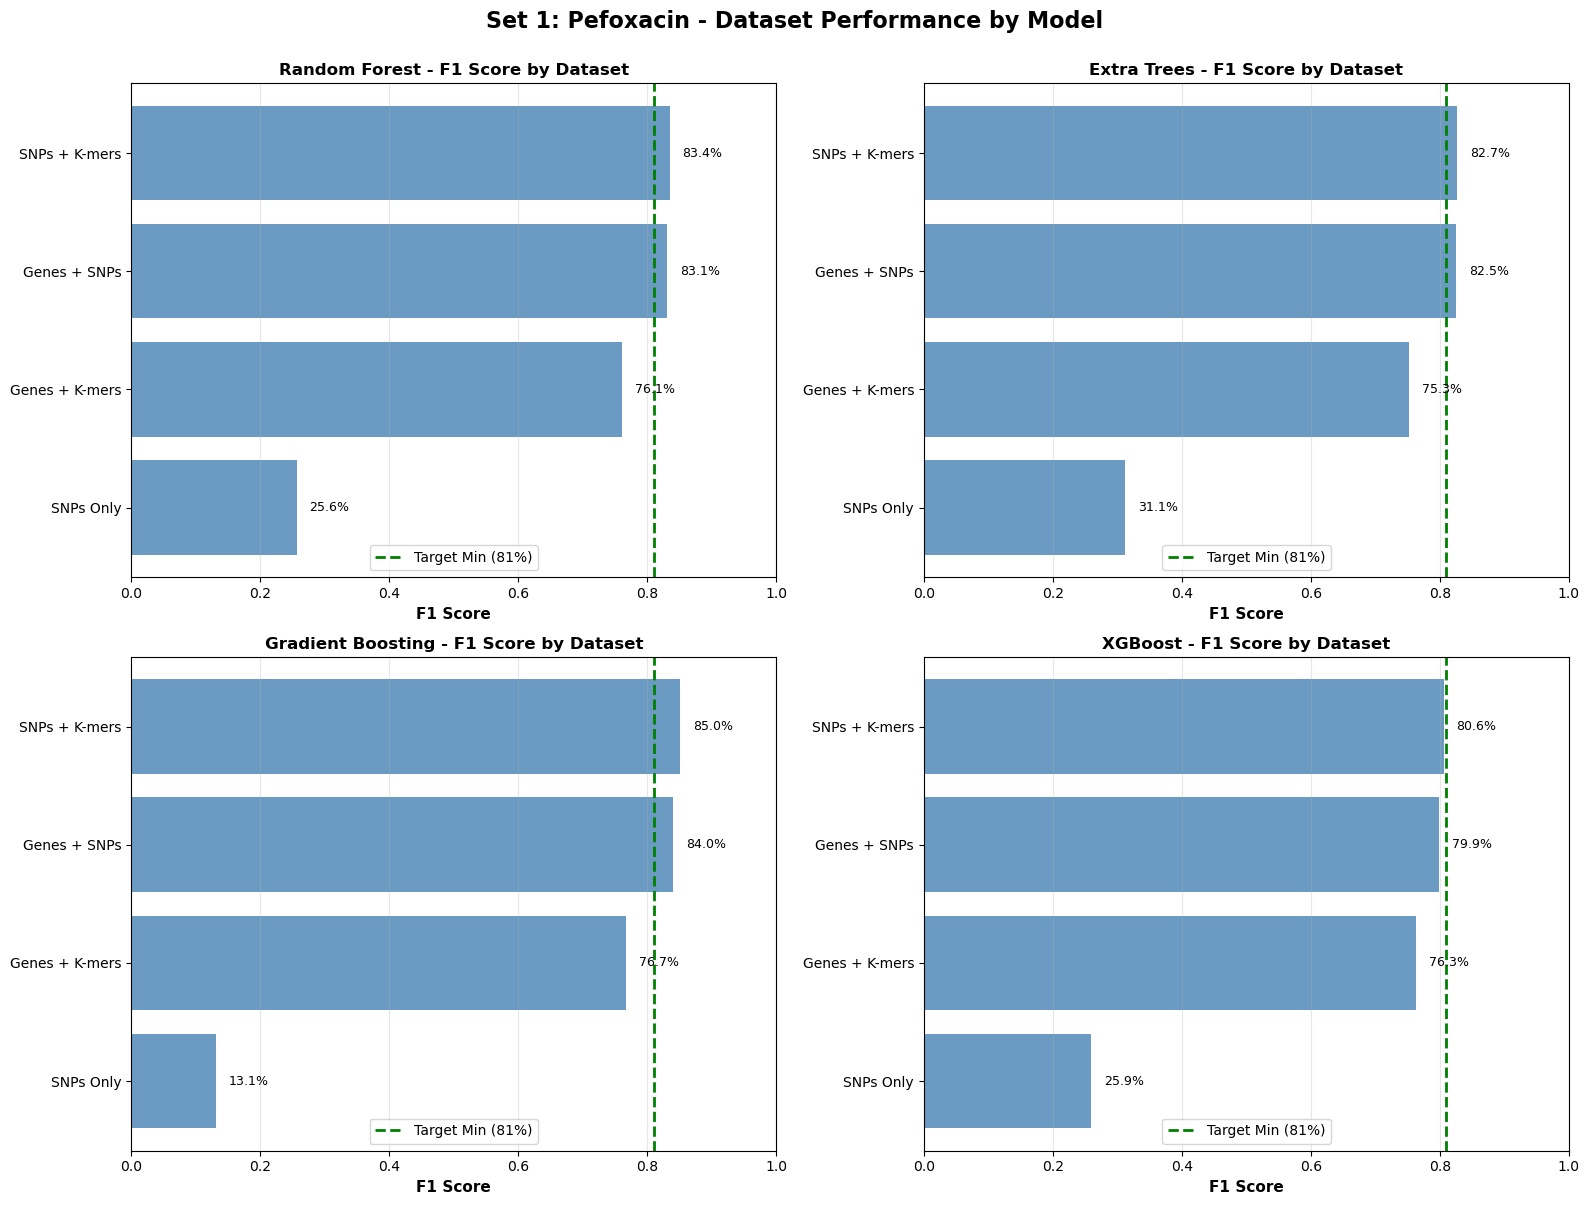

✓ Saved: Pefoxacin_dataset_comparison.png


In [10]:
# Visualization 1: Compare datasets by F1 Score for each model
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

models_list = results_df['Model'].unique()

for idx, model_name in enumerate(models_list):
    model_data = results_df[results_df['Model'] == model_name].sort_values('F1_Score')
    
    # Plot F1 Score
    axes[idx].barh(model_data['Dataset'], model_data['F1_Score'], color='steelblue', alpha=0.8)
    axes[idx].set_xlabel('F1 Score', fontsize=11, fontweight='bold')
    axes[idx].set_title(f'{model_name} - F1 Score by Dataset', fontsize=12, fontweight='bold')
    axes[idx].set_xlim([0, 1.0])
    axes[idx].axvline(x=0.81, color='green', linestyle='--', linewidth=2, label='Target Min (81%)')
    axes[idx].grid(axis='x', alpha=0.3)
    axes[idx].legend()
    
    # Add value labels
    for j, (dataset, f1) in enumerate(zip(model_data['Dataset'], model_data['F1_Score'])):
        axes[idx].text(f1 + 0.02, j, f'{f1*100:.1f}%', va='center', fontsize=9)

plt.suptitle(f'Set 1: {CONFIG["antibiotic"]} - Dataset Performance by Model', 
             fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.savefig(f'{CONFIG["antibiotic"]}_dataset_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"✓ Saved: {CONFIG['antibiotic']}_dataset_comparison.png")

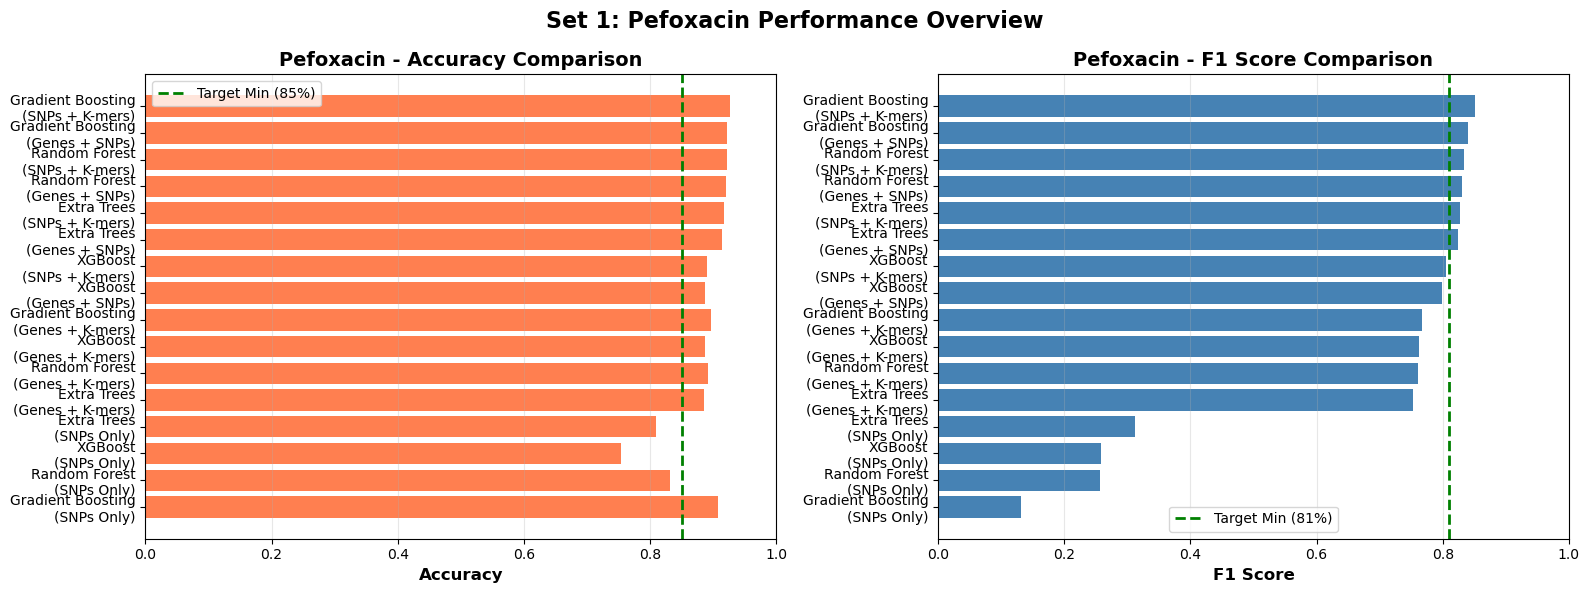

✓ Saved: Pefoxacin_accuracy_f1_comparison.png


In [11]:
# Visualization 2: Side-by-side comparison of Accuracy and F1 Score
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Prepare data
results_df['Model_Dataset'] = results_df['Model'] + '\n(' + results_df['Dataset'] + ')'
results_df_plot = results_df.sort_values('F1_Score', ascending=True)

# Plot 1: Accuracy
axes[0].barh(results_df_plot['Model_Dataset'], results_df_plot['Accuracy'], color='coral')
axes[0].set_xlabel('Accuracy', fontsize=12, fontweight='bold')
axes[0].set_title(f'{CONFIG["antibiotic"]} - Accuracy Comparison', fontsize=14, fontweight='bold')
axes[0].set_xlim([0, 1.0])
axes[0].axvline(x=0.85, color='green', linestyle='--', linewidth=2, label='Target Min (85%)')
axes[0].grid(axis='x', alpha=0.3)
axes[0].legend()

# Plot 2: F1 Score
axes[1].barh(results_df_plot['Model_Dataset'], results_df_plot['F1_Score'], color='steelblue')
axes[1].set_xlabel('F1 Score', fontsize=12, fontweight='bold')
axes[1].set_title(f'{CONFIG["antibiotic"]} - F1 Score Comparison', fontsize=14, fontweight='bold')
axes[1].set_xlim([0, 1.0])
axes[1].axvline(x=0.81, color='green', linestyle='--', linewidth=2, label='Target Min (81%)')
axes[1].grid(axis='x', alpha=0.3)
axes[1].legend()

plt.suptitle(f'Set 1: {CONFIG["antibiotic"]} Performance Overview', 
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{CONFIG["antibiotic"]}_accuracy_f1_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"✓ Saved: {CONFIG['antibiotic']}_accuracy_f1_comparison.png")

## FINAL MODEL TRAINING

In [12]:
print("\n" + "="*70)
print("TRAINING FINAL MODEL ON BEST DATASET")
print("="*70)

# Get best dataset and model
best_dataset_name = best_result['Dataset']
best_model_name = best_result['Model']
best_filepath = PEFOXACIN_FILES[best_dataset_name]

print(f"Best Dataset: {best_dataset_name}")
print(f"Best Model: {best_model_name}")
print(f"File: {best_filepath}")

# Load the best dataset
X_best, y_best = load_data(best_filepath, CONFIG['label_column'])

# Calculate scale_pos_weight
scale_pos_weight = (y_best == 0).sum() / (y_best == 1).sum()

# Get the best model
models = get_models(scale_pos_weight)
final_model = models[best_model_name]

# Train on full dataset
print(f"\nTraining {best_model_name} on full {best_dataset_name} dataset...")
final_model.fit(X_best, y_best)

print("✓ Final model trained successfully!")
print("\n⚠ Model NOT saved to pickle yet - awaiting your review")
print("="*70)


TRAINING FINAL MODEL ON BEST DATASET
Best Dataset: SNPs + K-mers
Best Model: Gradient Boosting
File: Downloads/salmonella_dna/398 files/snps_kmers_labels_398.csv
  ✓ Loaded: 398 samples × 10689 features
    Susceptible (0): 295 (74.1%)
    Resistant (1): 103 (25.9%)

Training Gradient Boosting on full SNPs + K-mers dataset...
✓ Final model trained successfully!

⚠ Model NOT saved to pickle yet - awaiting your review


## Feature Importances


FEATURE IMPORTANCE ANALYSIS

Top 20 Most Important Features:
Rank   Feature                                            Importance  
----------------------------------------------------------------------
1      NC_003197_3437381_A>T                              0.230830
2      QAMYDKLEGL                                         0.133416
3      TAYNPNAQAM                                         0.101921
4      LFHEAQAMWD                                         0.079816
5      AYNPNAQAMY                                         0.079791
6      VLFHEAQAMW                                         0.045774
7      FHEAQAMWDA                                         0.028127
8      NC_003197_3677765_T>C                              0.017965
9      NC_003197_3709210_C>T                              0.015371
10     AQAMYDKLEG                                         0.015057
11     RLTLWLPLYK                                         0.011544
12     NC_003197_2038714_G>A                              0

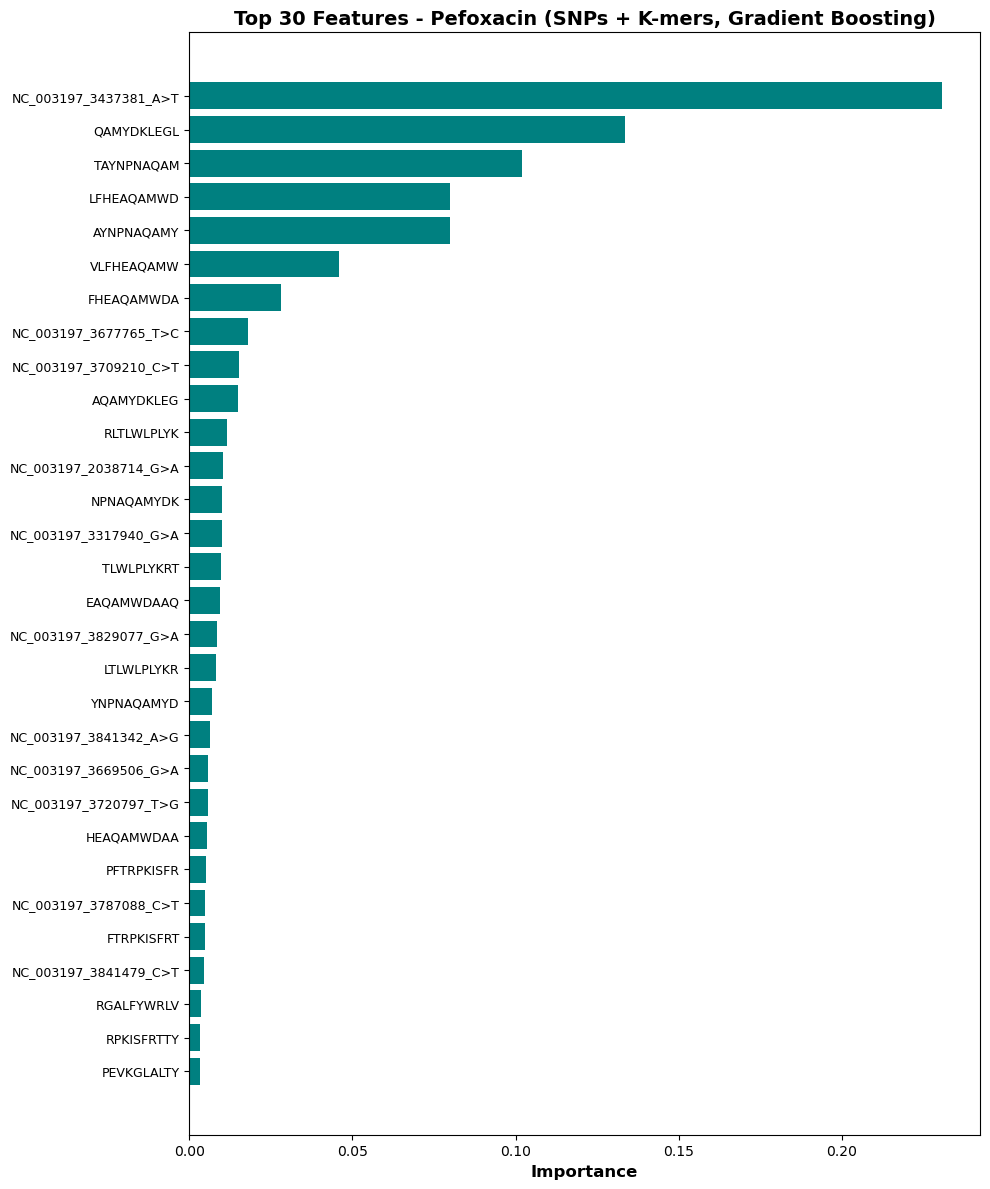


✓ Saved: Pefoxacin_feature_importance.png
✓ Saved: Pefoxacin_feature_importance.csv


In [13]:
# Feature importance (only for tree-based models)
if hasattr(final_model, 'feature_importances_'):
    print("\n" + "="*70)
    print("FEATURE IMPORTANCE ANALYSIS")
    print("="*70)
    
    # Get feature names
    feature_names = X_best.columns.tolist()
    importances = final_model.feature_importances_
    
    # Sort by importance
    indices = np.argsort(importances)[::-1]
    
    # Display top 20
    print(f"\nTop 20 Most Important Features:")
    print(f"{'Rank':<6} {'Feature':<50} {'Importance':<12}")
    print("-" * 70)
    
    for i in range(min(20, len(indices))):
        idx = indices[i]
        print(f"{i+1:<6} {feature_names[idx]:<50} {importances[idx]:.6f}")
    
    # Visualize top 30
    top_n = 30
    top_indices = indices[:top_n]
    top_features = [feature_names[i] for i in top_indices]
    top_importances = importances[top_indices]
    
    plt.figure(figsize=(10, 12))
    plt.barh(range(top_n), top_importances[::-1], color='teal')
    plt.yticks(range(top_n), top_features[::-1], fontsize=9)
    plt.xlabel('Importance', fontweight='bold', fontsize=12)
    plt.title(f'Top {top_n} Features - {CONFIG["antibiotic"]} ({best_dataset_name}, {best_model_name})', 
              fontweight='bold', fontsize=14)
    plt.tight_layout()
    plt.savefig(f'{CONFIG["antibiotic"]}_feature_importance.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"\n✓ Saved: {CONFIG['antibiotic']}_feature_importance.png")
    
    # Save feature importance to CSV
    importance_df = pd.DataFrame({
        'Feature': [feature_names[i] for i in indices],
        'Importance': importances[indices]
    })
    importance_df.to_csv(f'{CONFIG["antibiotic"]}_feature_importance.csv', index=False)
    print(f"✓ Saved: {CONFIG['antibiotic']}_feature_importance.csv")
    
else:
    print(f"\n⚠ {best_model_name} does not support feature importance extraction")

# SET 2 TRAINING ON TRIMETHOROPIN

In [14]:
# File paths for Trimethoprim datasets (Set 2)
TRIMETHOPRIM_FILES = {
    'Genes + K-mers': 'Downloads/salmonella_dna/398 files/genes_kmers_trim_labels_398.csv',
    'Genes + SNPs': 'Downloads/salmonella_dna/398 files/genes_snps_trim_labels_398.csv',
    'SNPs Only': 'Downloads/salmonella_dna/398 files/snps_only_labels_trim_398.csv',
    'SNPs + K-mers': 'Downloads/salmonella_dna/398 files/snps_kmers_trim_labels_398.csv'
}

# Update configuration for Set 2
CONFIG['antibiotic'] = 'Trimethoprim'
CONFIG['label_column'] = 'Trimethoprim_Phenotype'

print("\n" + "="*70)
print(f"SET 2: {CONFIG['antibiotic']} Resistance Prediction")
print("="*70)
print(f"Number of dataset variants: {len(TRIMETHOPRIM_FILES)}")
print(f"Cross-validation folds: {CONFIG['n_folds']}")
print("="*70)


SET 2: Trimethoprim Resistance Prediction
Number of dataset variants: 4
Cross-validation folds: 6


In [15]:
def load_data_trimethoprim(filepath, label_column):
    """Load CSV and separate features from labels for Trimethoprim"""
    df = pd.read_csv(filepath)
    
    # Remove Genome_ID and label column to get features
    X = df.drop(columns=['Genome_ID', label_column])
    y = df[label_column]
    
    # Validate
    assert len(X) == len(y), "Mismatch in samples"
    assert y.isin([0, 1]).all(), "Labels must be 0 (susceptible) or 1 (resistant)"
    
    print(f"  ✓ Loaded: {len(X)} samples × {X.shape[1]} features")
    print(f"    Susceptible (0): {(y==0).sum()} ({(y==0).sum()/len(y)*100:.1f}%)")
    print(f"    Resistant (1): {(y==1).sum()} ({(y==1).sum()/len(y)*100:.1f}%)")
    
    return X, y

print("✓ Trimethoprim data loader ready")

✓ Trimethoprim data loader ready


In [16]:
# Storage for Trimethoprim results
trimethoprim_results = []

print("\n" + "="*70)
print(f"TRAINING MODELS FOR SET 2: {CONFIG['antibiotic']}")
print("="*70)

for dataset_name, filepath in TRIMETHOPRIM_FILES.items():
    print(f"\n{'='*70}")
    print(f"Dataset Variant: {dataset_name}")
    print(f"{'='*70}")
    
    # Load data
    X, y = load_data_trimethoprim(filepath, CONFIG['label_column'])
    
    # Calculate class weight for XGBoost
    n_susceptible = (y == 0).sum()
    n_resistant = (y == 1).sum()
    scale_pos_weight = n_susceptible / n_resistant if n_resistant > 0 else 1.0
    
    print(f"  Class imbalance ratio: {scale_pos_weight:.2f}")
    
    # Get models
    models = get_models(scale_pos_weight)
    
    # Train each model
    for model_name, model in models.items():
        print(f"\n  Training: {model_name}...")
        
        # Cross-validation
        metrics = evaluate_model_cv(X, y, model, n_folds=CONFIG['n_folds'])
        
        # Store results
        trimethoprim_results.append({
            'Antibiotic': CONFIG['antibiotic'],
            'Dataset': dataset_name,
            'Model': model_name,
            'Accuracy': metrics['accuracy'],
            'Precision': metrics['precision'],
            'Recall': metrics['recall'],
            'F1_Score': metrics['f1']
        })
        
        print(f"    ✓ Accuracy:  {metrics['accuracy']*100:.2f}%")
        print(f"    ✓ Precision: {metrics['precision']*100:.2f}%")
        print(f"    ✓ Recall:    {metrics['recall']*100:.2f}%")
        print(f"    ✓ F1 Score:  {metrics['f1']*100:.2f}%")

print("\n" + "="*70)
print("✓ TRAINING COMPLETE FOR SET 2")
print("="*70)


TRAINING MODELS FOR SET 2: Trimethoprim

Dataset Variant: Genes + K-mers
  ✓ Loaded: 398 samples × 5160 features
    Susceptible (0): 211 (53.0%)
    Resistant (1): 187 (47.0%)
  Class imbalance ratio: 1.13

  Training: Random Forest...
    ✓ Accuracy:  91.21%
    ✓ Precision: 92.77%
    ✓ Recall:    88.74%
    ✓ F1 Score:  90.44%

  Training: Extra Trees...
    ✓ Accuracy:  91.46%
    ✓ Precision: 92.86%
    ✓ Recall:    89.28%
    ✓ F1 Score:  90.73%

  Training: Gradient Boosting...
    ✓ Accuracy:  90.96%
    ✓ Precision: 94.72%
    ✓ Recall:    86.06%
    ✓ F1 Score:  89.86%

  Training: XGBoost...
    ✓ Accuracy:  91.21%
    ✓ Precision: 92.77%
    ✓ Recall:    88.74%
    ✓ F1 Score:  90.41%

Dataset Variant: Genes + SNPs
  ✓ Loaded: 398 samples × 5751 features
    Susceptible (0): 211 (53.0%)
    Resistant (1): 187 (47.0%)
  Class imbalance ratio: 1.13

  Training: Random Forest...
    ✓ Accuracy:  95.24%
    ✓ Precision: 98.25%
    ✓ Recall:    91.45%
    ✓ F1 Score:  94.70%



In [17]:
# Create DataFrame from Trimethoprim results
trimethoprim_df = pd.DataFrame(trimethoprim_results)

# Sort by F1 Score (descending)
trimethoprim_df_sorted = trimethoprim_df.sort_values('F1_Score', ascending=False)

print("\n" + "="*70)
print(f"SUMMARY RESULTS - SET 2: {CONFIG['antibiotic']}")
print("="*70)
print(trimethoprim_df_sorted.to_string(index=False))
print("="*70)

# Save to CSV
output_filename = f'{CONFIG["antibiotic"]}_training_summary.csv'
trimethoprim_df.to_csv(output_filename, index=False)
print(f"\n✓ Results saved to: {output_filename}")


SUMMARY RESULTS - SET 2: Trimethoprim
  Antibiotic        Dataset             Model  Accuracy  Precision   Recall  F1_Score
Trimethoprim  SNPs + K-mers       Extra Trees  0.954809   0.972520 0.930276  0.950331
Trimethoprim  SNPs + K-mers     Random Forest  0.952322   0.972137 0.924899  0.947325
Trimethoprim   Genes + SNPs     Random Forest  0.952359   0.982540 0.914483  0.946969
Trimethoprim  SNPs + K-mers           XGBoost  0.949834   0.971969 0.919691  0.944401
Trimethoprim   Genes + SNPs       Extra Trees  0.949796   0.977316 0.914483  0.944219
Trimethoprim  SNPs + K-mers Gradient Boosting  0.947347   0.966796 0.919691  0.942138
Trimethoprim   Genes + SNPs           XGBoost  0.942258   0.951205 0.925067  0.937480
Trimethoprim   Genes + SNPs Gradient Boosting  0.937321   0.940432 0.925235  0.932540
Trimethoprim Genes + K-mers       Extra Trees  0.914631   0.928565 0.892809  0.907316
Trimethoprim Genes + K-mers     Random Forest  0.912144   0.927674 0.887433  0.904351
Trimethoprim Ge

In [18]:
# Find best performing combination
best_trim = trimethoprim_df_sorted.iloc[0]

print("\n" + "="*70)
print("BEST PERFORMING MODEL")
print("="*70)
print(f"Dataset Variant: {best_trim['Dataset']}")
print(f"Model: {best_trim['Model']}")
print(f"Accuracy: {best_trim['Accuracy']*100:.2f}%")
print(f"Precision: {best_trim['Precision']*100:.2f}%")
print(f"Recall: {best_trim['Recall']*100:.2f}%")
print(f"F1 Score: {best_trim['F1_Score']*100:.2f}%")
print("="*70)

# Check if meets target metrics
meets_f1_target = 0.81 <= best_trim['F1_Score'] <= 0.99
meets_acc_target = 0.85 <= best_trim['Accuracy'] <= 0.99

print(f"\n{'='*70}")
print("TARGET METRICS EVALUATION")
print("="*70)
print(f"F1 Score Target (81-99%): {'✓ PASS' if meets_f1_target else '✗ FAIL'}")
print(f"Accuracy Target (85-99%): {'✓ PASS' if meets_acc_target else '✗ FAIL'}")
print("="*70)


BEST PERFORMING MODEL
Dataset Variant: SNPs + K-mers
Model: Extra Trees
Accuracy: 95.48%
Precision: 97.25%
Recall: 93.03%
F1 Score: 95.03%

TARGET METRICS EVALUATION
F1 Score Target (81-99%): ✓ PASS
Accuracy Target (85-99%): ✓ PASS


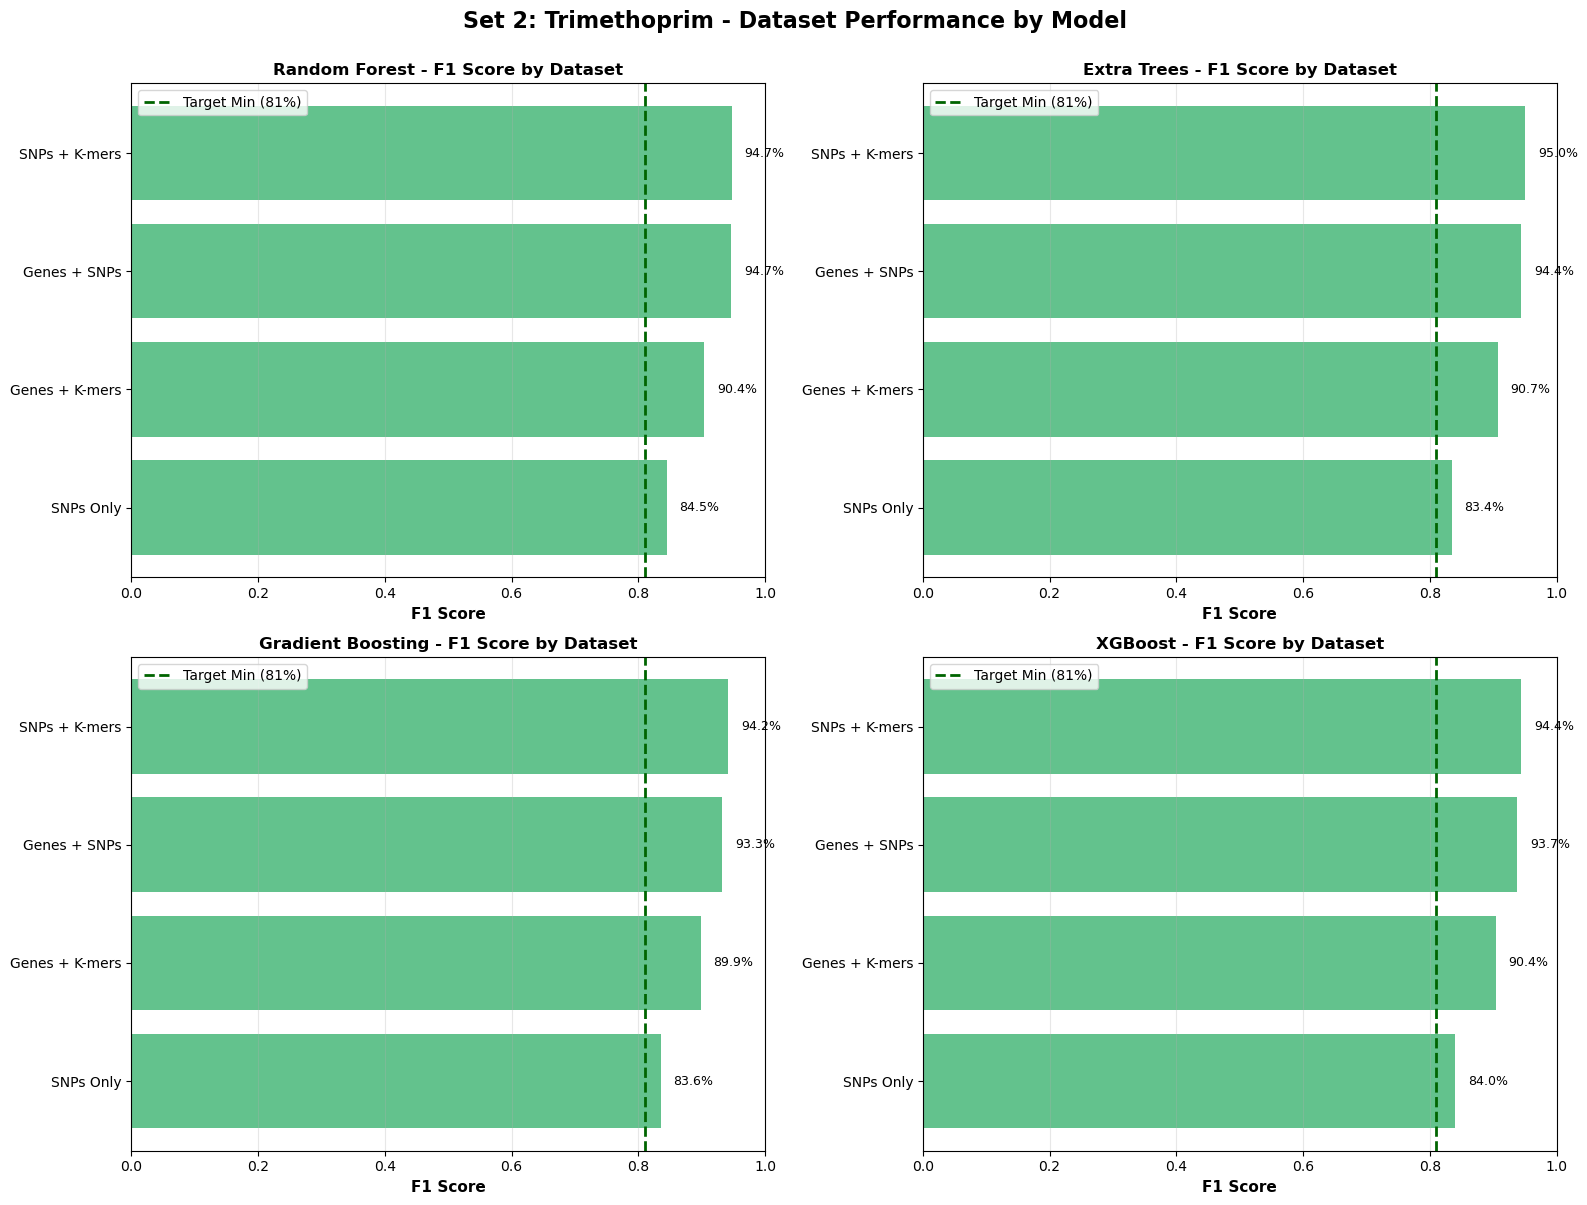

✓ Saved: Trimethoprim_dataset_comparison.png


In [19]:
# Visualization 1: Compare datasets by F1 Score for each model
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

models_list = trimethoprim_df['Model'].unique()

for idx, model_name in enumerate(models_list):
    model_data = trimethoprim_df[trimethoprim_df['Model'] == model_name].sort_values('F1_Score')
    
    # Plot F1 Score
    axes[idx].barh(model_data['Dataset'], model_data['F1_Score'], color='mediumseagreen', alpha=0.8)
    axes[idx].set_xlabel('F1 Score', fontsize=11, fontweight='bold')
    axes[idx].set_title(f'{model_name} - F1 Score by Dataset', fontsize=12, fontweight='bold')
    axes[idx].set_xlim([0, 1.0])
    axes[idx].axvline(x=0.81, color='darkgreen', linestyle='--', linewidth=2, label='Target Min (81%)')
    axes[idx].grid(axis='x', alpha=0.3)
    axes[idx].legend()
    
    # Add value labels
    for j, (dataset, f1) in enumerate(zip(model_data['Dataset'], model_data['F1_Score'])):
        axes[idx].text(f1 + 0.02, j, f'{f1*100:.1f}%', va='center', fontsize=9)

plt.suptitle(f'Set 2: {CONFIG["antibiotic"]} - Dataset Performance by Model', 
             fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.savefig(f'{CONFIG["antibiotic"]}_dataset_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"✓ Saved: {CONFIG['antibiotic']}_dataset_comparison.png")

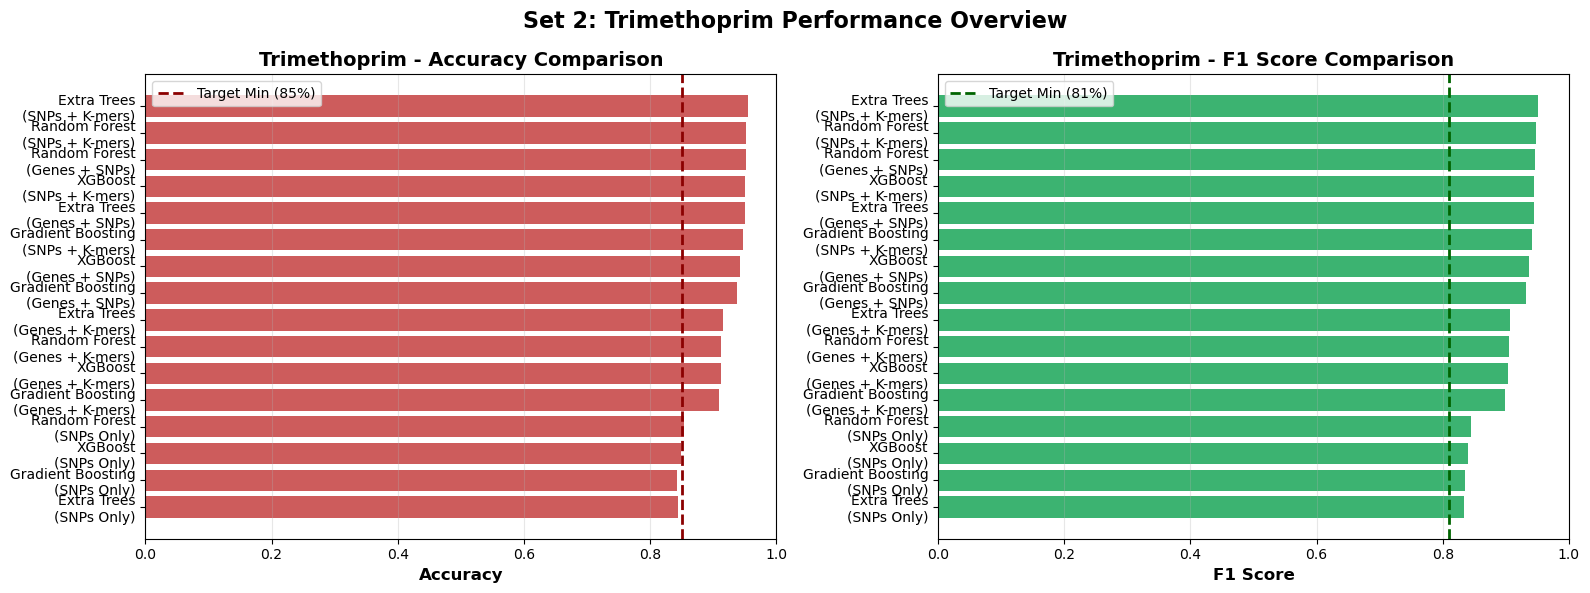

✓ Saved: Trimethoprim_accuracy_f1_comparison.png


In [20]:
# Visualization 2: Side-by-side comparison of Accuracy and F1 Score
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Prepare data
trimethoprim_df['Model_Dataset'] = trimethoprim_df['Model'] + '\n(' + trimethoprim_df['Dataset'] + ')'
trimethoprim_df_plot = trimethoprim_df.sort_values('F1_Score', ascending=True)

# Plot 1: Accuracy
axes[0].barh(trimethoprim_df_plot['Model_Dataset'], trimethoprim_df_plot['Accuracy'], color='indianred')
axes[0].set_xlabel('Accuracy', fontsize=12, fontweight='bold')
axes[0].set_title(f'{CONFIG["antibiotic"]} - Accuracy Comparison', fontsize=14, fontweight='bold')
axes[0].set_xlim([0, 1.0])
axes[0].axvline(x=0.85, color='darkred', linestyle='--', linewidth=2, label='Target Min (85%)')
axes[0].grid(axis='x', alpha=0.3)
axes[0].legend()

# Plot 2: F1 Score
axes[1].barh(trimethoprim_df_plot['Model_Dataset'], trimethoprim_df_plot['F1_Score'], color='mediumseagreen')
axes[1].set_xlabel('F1 Score', fontsize=12, fontweight='bold')
axes[1].set_title(f'{CONFIG["antibiotic"]} - F1 Score Comparison', fontsize=14, fontweight='bold')
axes[1].set_xlim([0, 1.0])
axes[1].axvline(x=0.81, color='darkgreen', linestyle='--', linewidth=2, label='Target Min (81%)')
axes[1].grid(axis='x', alpha=0.3)
axes[1].legend()

plt.suptitle(f'Set 2: {CONFIG["antibiotic"]} Performance Overview', 
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{CONFIG["antibiotic"]}_accuracy_f1_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"✓ Saved: {CONFIG['antibiotic']}_accuracy_f1_comparison.png")

In [21]:
print("\n" + "="*70)
print("TRAINING FINAL MODEL ON BEST DATASET")
print("="*70)

# Get best dataset and model
best_dataset_name_trim = best_trim['Dataset']
best_model_name_trim = best_trim['Model']
best_filepath_trim = TRIMETHOPRIM_FILES[best_dataset_name_trim]

print(f"Best Dataset: {best_dataset_name_trim}")
print(f"Best Model: {best_model_name_trim}")
print(f"File: {best_filepath_trim}")

# Load the best dataset
X_best_trim, y_best_trim = load_data_trimethoprim(best_filepath_trim, CONFIG['label_column'])

# Calculate scale_pos_weight
scale_pos_weight_trim = (y_best_trim == 0).sum() / (y_best_trim == 1).sum()

# Get the best model
models_trim = get_models(scale_pos_weight_trim)
final_model_trim = models_trim[best_model_name_trim]

# Train on full dataset
print(f"\nTraining {best_model_name_trim} on full {best_dataset_name_trim} dataset...")
final_model_trim.fit(X_best_trim, y_best_trim)

print("✓ Final model trained successfully!")
print("\n⚠ Model NOT saved to pickle yet - awaiting your review")
print("="*70)


TRAINING FINAL MODEL ON BEST DATASET
Best Dataset: SNPs + K-mers
Best Model: Extra Trees
File: Downloads/salmonella_dna/398 files/snps_kmers_trim_labels_398.csv
  ✓ Loaded: 398 samples × 10689 features
    Susceptible (0): 211 (53.0%)
    Resistant (1): 187 (47.0%)

Training Extra Trees on full SNPs + K-mers dataset...
✓ Final model trained successfully!

⚠ Model NOT saved to pickle yet - awaiting your review



FEATURE IMPORTANCE ANALYSIS

Top 20 Most Important Features:
Rank   Feature                                            Importance  
----------------------------------------------------------------------
1      AKSSAKLVVM                                         0.016338
2      LAKSSAKLVV                                         0.016074
3      RIAALTGAGI                                         0.015803
4      QADRREAPAG                                         0.015776
5      APAGDIMDHI                                         0.015640
6      AFFDARIAAL                                         0.015634
7      DGLAVLAALK                                         0.015521
8      EGACLVITAI                                         0.015075
9      MFMPPVFPAH                                         0.015034
10     SRGVAYLNDI                                         0.008574
11     HIAAFFDARI                                         0.008530
12     RYLAPDAAIA                                         0

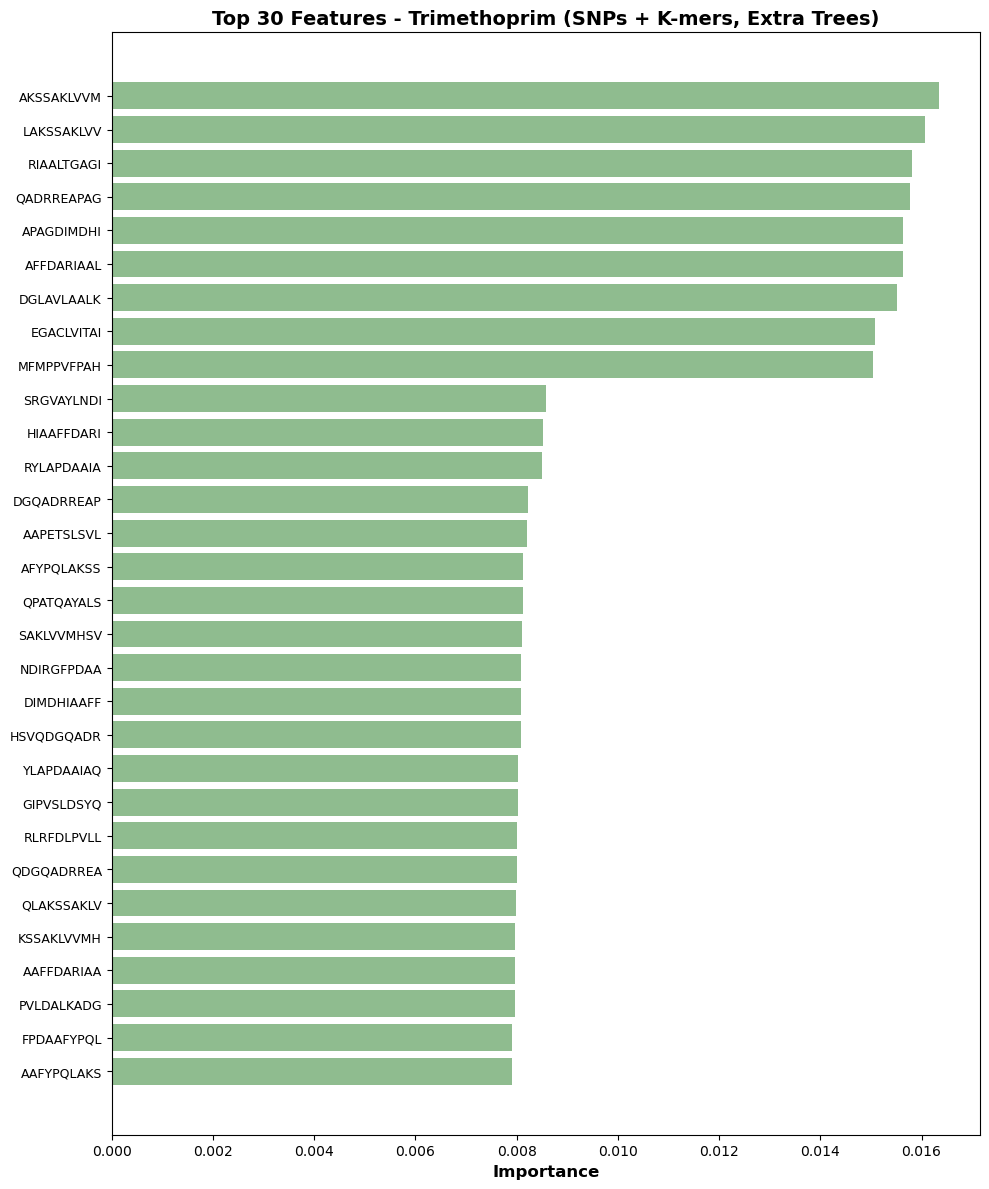


✓ Saved: Trimethoprim_feature_importance.png
✓ Saved: Trimethoprim_feature_importance.csv


In [22]:
# Feature importance (only for tree-based models)
if hasattr(final_model_trim, 'feature_importances_'):
    print("\n" + "="*70)
    print("FEATURE IMPORTANCE ANALYSIS")
    print("="*70)
    
    # Get feature names
    feature_names_trim = X_best_trim.columns.tolist()
    importances_trim = final_model_trim.feature_importances_
    
    # Sort by importance
    indices_trim = np.argsort(importances_trim)[::-1]
    
    # Display top 20
    print(f"\nTop 20 Most Important Features:")
    print(f"{'Rank':<6} {'Feature':<50} {'Importance':<12}")
    print("-" * 70)
    
    for i in range(min(20, len(indices_trim))):
        idx = indices_trim[i]
        print(f"{i+1:<6} {feature_names_trim[idx]:<50} {importances_trim[idx]:.6f}")
    
    # Visualize top 30
    top_n = 30
    top_indices_trim = indices_trim[:top_n]
    top_features_trim = [feature_names_trim[i] for i in top_indices_trim]
    top_importances_trim = importances_trim[top_indices_trim]
    
    plt.figure(figsize=(10, 12))
    plt.barh(range(top_n), top_importances_trim[::-1], color='darkseagreen')
    plt.yticks(range(top_n), top_features_trim[::-1], fontsize=9)
    plt.xlabel('Importance', fontweight='bold', fontsize=12)
    plt.title(f'Top {top_n} Features - {CONFIG["antibiotic"]} ({best_dataset_name_trim}, {best_model_name_trim})', 
              fontweight='bold', fontsize=14)
    plt.tight_layout()
    plt.savefig(f'{CONFIG["antibiotic"]}_feature_importance.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"\n✓ Saved: {CONFIG['antibiotic']}_feature_importance.png")
    
    # Save feature importance to CSV
    importance_df_trim = pd.DataFrame({
        'Feature': [feature_names_trim[i] for i in indices_trim],
        'Importance': importances_trim[indices_trim]
    })
    importance_df_trim.to_csv(f'{CONFIG["antibiotic"]}_feature_importance.csv', index=False)
    print(f"✓ Saved: {CONFIG['antibiotic']}_feature_importance.csv")
    
else:
    print(f"\n⚠ {best_model_name_trim} does not support feature importance extraction")

In [23]:
# Compare which dataset performed best across antibiotics
print("\n" + "="*70)
print("CROSS-SET COMPARISON: PEFOXACIN vs TRIMETHOPRIM")
print("="*70)

print("\nSet 1 - Pefoxacin Best:")
print(f"  Dataset: {best_result['Dataset']}")
print(f"  Model: {best_result['Model']}")
print(f"  F1 Score: {best_result['F1_Score']*100:.2f}%")
print(f"  Accuracy: {best_result['Accuracy']*100:.2f}%")

print("\nSet 2 - Trimethoprim Best:")
print(f"  Dataset: {best_trim['Dataset']}")
print(f"  Model: {best_trim['Model']}")
print(f"  F1 Score: {best_trim['F1_Score']*100:.2f}%")
print(f"  Accuracy: {best_trim['Accuracy']*100:.2f}%")

# Check if same dataset emerged as best
same_dataset = best_result['Dataset'] == best_trim['Dataset']
same_model = best_result['Model'] == best_trim['Model']

print(f"\n{'='*70}")
print(f"Same best dataset across sets? {'YES ✓' if same_dataset else 'NO ✗'}")
print(f"Same best model across sets? {'YES ✓' if same_model else 'NO ✗'}")
print("="*70)


CROSS-SET COMPARISON: PEFOXACIN vs TRIMETHOPRIM

Set 1 - Pefoxacin Best:
  Dataset: SNPs + K-mers
  Model: Gradient Boosting
  F1 Score: 85.05%
  Accuracy: 92.70%

Set 2 - Trimethoprim Best:
  Dataset: SNPs + K-mers
  Model: Extra Trees
  F1 Score: 95.03%
  Accuracy: 95.48%

Same best dataset across sets? YES ✓
Same best model across sets? NO ✗


# SET 3 TRAINING ON Sulfamethoxazole

In [24]:
# File paths for Sulfamethoxazole datasets (Set 3)
SULFAMETHOXAZOLE_FILES = {
    'Genes + K-mers': 'Downloads/salmonella_dna/398 files/genes_kmers_sulf_labels_398.csv',
    'Genes + SNPs': 'Downloads/salmonella_dna/398 files/genes_snps_sulf_labels_398.csv',
    'SNPs Only': 'Downloads/salmonella_dna/398 files/snps_only_labels_sulf_398.csv',
    'SNPs + K-mers': 'Downloads/salmonella_dna/398 files/snps_kmers_sulf_labels_398.csv'
}

# Update configuration for Set 3
CONFIG['antibiotic'] = 'Sulfamethoxazole'
CONFIG['label_column'] = 'Sulfamethoxazole_Phenotype'

print("\n" + "="*70)
print(f"SET 3: {CONFIG['antibiotic']} Resistance Prediction")
print("="*70)
print(f"Number of dataset variants: {len(SULFAMETHOXAZOLE_FILES)}")
print(f"Cross-validation folds: {CONFIG['n_folds']}")
print("="*70)


SET 3: Sulfamethoxazole Resistance Prediction
Number of dataset variants: 4
Cross-validation folds: 6


In [25]:
def load_data_sulfamethoxazole(filepath, label_column):
    """Load CSV and separate features from labels for Sulfamethoxazole"""
    df = pd.read_csv(filepath)
    
    # Remove Genome_ID and label column to get features
    X = df.drop(columns=['Genome_ID', label_column])
    y = df[label_column]
    
    # Validate
    assert len(X) == len(y), "Mismatch in samples"
    assert y.isin([0, 1]).all(), "Labels must be 0 (susceptible) or 1 (resistant)"
    
    print(f"  ✓ Loaded: {len(X)} samples × {X.shape[1]} features")
    print(f"    Susceptible (0): {(y==0).sum()} ({(y==0).sum()/len(y)*100:.1f}%)")
    print(f"    Resistant (1): {(y==1).sum()} ({(y==1).sum()/len(y)*100:.1f}%)")
    
    return X, y

print("✓ Sulfamethoxazole data loader ready")

✓ Sulfamethoxazole data loader ready


In [26]:
# Storage for Sulfamethoxazole results
sulfamethoxazole_results = []

print("\n" + "="*70)
print(f"TRAINING MODELS FOR SET 3: {CONFIG['antibiotic']}")
print("="*70)

for dataset_name, filepath in SULFAMETHOXAZOLE_FILES.items():
    print(f"\n{'='*70}")
    print(f"Dataset Variant: {dataset_name}")
    print(f"{'='*70}")
    
    # Load data
    X, y = load_data_sulfamethoxazole(filepath, CONFIG['label_column'])
    
    # Calculate class weight for XGBoost
    n_susceptible = (y == 0).sum()
    n_resistant = (y == 1).sum()
    scale_pos_weight = n_susceptible / n_resistant if n_resistant > 0 else 1.0
    
    print(f"  Class imbalance ratio: {scale_pos_weight:.2f}")
    
    # Get models
    models = get_models(scale_pos_weight)
    
    # Train each model
    for model_name, model in models.items():
        print(f"\n  Training: {model_name}...")
        
        # Cross-validation
        metrics = evaluate_model_cv(X, y, model, n_folds=CONFIG['n_folds'])
        
        # Store results
        sulfamethoxazole_results.append({
            'Antibiotic': CONFIG['antibiotic'],
            'Dataset': dataset_name,
            'Model': model_name,
            'Accuracy': metrics['accuracy'],
            'Precision': metrics['precision'],
            'Recall': metrics['recall'],
            'F1_Score': metrics['f1']
        })
        
        print(f"    ✓ Accuracy:  {metrics['accuracy']*100:.2f}%")
        print(f"    ✓ Precision: {metrics['precision']*100:.2f}%")
        print(f"    ✓ Recall:    {metrics['recall']*100:.2f}%")
        print(f"    ✓ F1 Score:  {metrics['f1']*100:.2f}%")

print("\n" + "="*70)
print("✓ TRAINING COMPLETE FOR SET 3")
print("="*70)


TRAINING MODELS FOR SET 3: Sulfamethoxazole

Dataset Variant: Genes + K-mers
  ✓ Loaded: 398 samples × 5160 features
    Susceptible (0): 237 (59.5%)
    Resistant (1): 161 (40.5%)
  Class imbalance ratio: 1.47

  Training: Random Forest...
    ✓ Accuracy:  92.19%
    ✓ Precision: 94.54%
    ✓ Recall:    85.75%
    ✓ F1 Score:  89.70%

  Training: Extra Trees...
    ✓ Accuracy:  93.20%
    ✓ Precision: 94.68%
    ✓ Recall:    88.22%
    ✓ F1 Score:  91.22%

  Training: Gradient Boosting...
    ✓ Accuracy:  91.70%
    ✓ Precision: 93.99%
    ✓ Recall:    85.14%
    ✓ F1 Score:  89.08%

  Training: XGBoost...
    ✓ Accuracy:  91.95%
    ✓ Precision: 94.09%
    ✓ Recall:    85.75%
    ✓ F1 Score:  89.44%

Dataset Variant: Genes + SNPs
  ✓ Loaded: 398 samples × 5751 features
    Susceptible (0): 237 (59.5%)
    Resistant (1): 161 (40.5%)
  Class imbalance ratio: 1.47

  Training: Random Forest...
    ✓ Accuracy:  93.45%
    ✓ Precision: 94.49%
    ✓ Recall:    89.48%
    ✓ F1 Score:  91.4

In [27]:
# Create DataFrame from Sulfamethoxazole results
sulfamethoxazole_df = pd.DataFrame(sulfamethoxazole_results)

# Sort by F1 Score (descending)
sulfamethoxazole_df_sorted = sulfamethoxazole_df.sort_values('F1_Score', ascending=False)

print("\n" + "="*70)
print(f"SUMMARY RESULTS - SET 3: {CONFIG['antibiotic']}")
print("="*70)
print(sulfamethoxazole_df_sorted.to_string(index=False))
print("="*70)

# Save to CSV
output_filename = f'{CONFIG["antibiotic"]}_training_summary.csv'
sulfamethoxazole_df.to_csv(output_filename, index=False)
print(f"\n✓ Results saved to: {output_filename}")


SUMMARY RESULTS - SET 3: Sulfamethoxazole
      Antibiotic        Dataset             Model  Accuracy  Precision   Recall  F1_Score
Sulfamethoxazole   Genes + SNPs Gradient Boosting  0.952133   0.950291 0.931861  0.940456
Sulfamethoxazole  SNPs + K-mers Gradient Boosting  0.952171   0.961937 0.919516  0.939107
Sulfamethoxazole   Genes + SNPs           XGBoost  0.947083   0.949956 0.919516  0.933294
Sulfamethoxazole  SNPs + K-mers       Extra Trees  0.944595   0.948755 0.913343  0.929416
Sulfamethoxazole  SNPs + K-mers           XGBoost  0.942108   0.955443 0.900997  0.925363
Sulfamethoxazole  SNPs + K-mers     Random Forest  0.939545   0.953699 0.894824  0.921002
Sulfamethoxazole   Genes + SNPs       Extra Trees  0.937057   0.950460 0.894824  0.917509
Sulfamethoxazole   Genes + SNPs     Random Forest  0.934532   0.944948 0.894824  0.914703
Sulfamethoxazole Genes + K-mers       Extra Trees  0.932044   0.946759 0.882241  0.912239
Sulfamethoxazole Genes + K-mers     Random Forest  0.9219

In [28]:
# Find best performing combination
best_sulfa = sulfamethoxazole_df_sorted.iloc[0]

print("\n" + "="*70)
print("BEST PERFORMING MODEL")
print("="*70)
print(f"Dataset Variant: {best_sulfa['Dataset']}")
print(f"Model: {best_sulfa['Model']}")
print(f"Accuracy: {best_sulfa['Accuracy']*100:.2f}%")
print(f"Precision: {best_sulfa['Precision']*100:.2f}%")
print(f"Recall: {best_sulfa['Recall']*100:.2f}%")
print(f"F1 Score: {best_sulfa['F1_Score']*100:.2f}%")
print("="*70)

# Check if meets target metrics
meets_f1_target = 0.81 <= best_sulfa['F1_Score'] <= 0.99
meets_acc_target = 0.85 <= best_sulfa['Accuracy'] <= 0.99

print(f"\n{'='*70}")
print("TARGET METRICS EVALUATION")
print("="*70)
print(f"F1 Score Target (81-99%): {'✓ PASS' if meets_f1_target else '✗ FAIL'}")
print(f"Accuracy Target (85-99%): {'✓ PASS' if meets_acc_target else '✗ FAIL'}")
print("="*70)


BEST PERFORMING MODEL
Dataset Variant: Genes + SNPs
Model: Gradient Boosting
Accuracy: 95.21%
Precision: 95.03%
Recall: 93.19%
F1 Score: 94.05%

TARGET METRICS EVALUATION
F1 Score Target (81-99%): ✓ PASS
Accuracy Target (85-99%): ✓ PASS


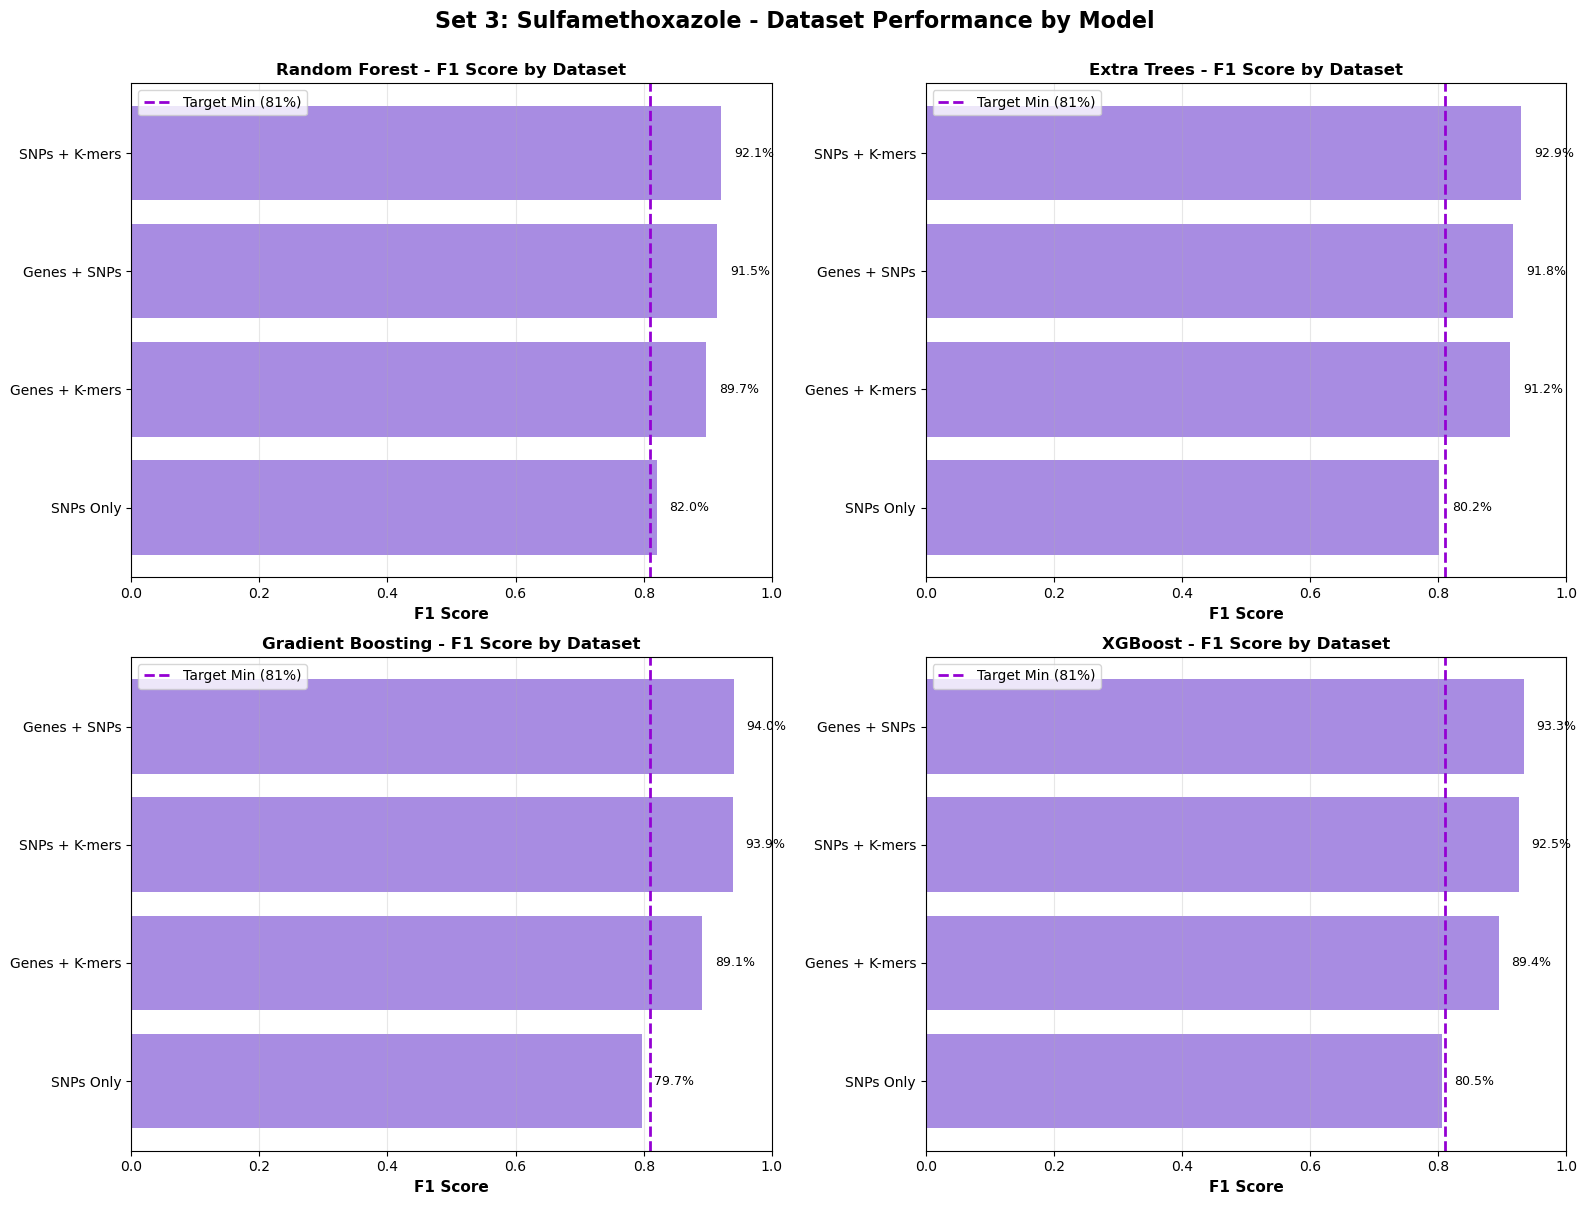

✓ Saved: Sulfamethoxazole_dataset_comparison.png


In [29]:
# Visualization 1: Compare datasets by F1 Score for each model
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

models_list = sulfamethoxazole_df['Model'].unique()

for idx, model_name in enumerate(models_list):
    model_data = sulfamethoxazole_df[sulfamethoxazole_df['Model'] == model_name].sort_values('F1_Score')
    
    # Plot F1 Score
    axes[idx].barh(model_data['Dataset'], model_data['F1_Score'], color='mediumpurple', alpha=0.8)
    axes[idx].set_xlabel('F1 Score', fontsize=11, fontweight='bold')
    axes[idx].set_title(f'{model_name} - F1 Score by Dataset', fontsize=12, fontweight='bold')
    axes[idx].set_xlim([0, 1.0])
    axes[idx].axvline(x=0.81, color='darkviolet', linestyle='--', linewidth=2, label='Target Min (81%)')
    axes[idx].grid(axis='x', alpha=0.3)
    axes[idx].legend()
    
    # Add value labels
    for j, (dataset, f1) in enumerate(zip(model_data['Dataset'], model_data['F1_Score'])):
        axes[idx].text(f1 + 0.02, j, f'{f1*100:.1f}%', va='center', fontsize=9)

plt.suptitle(f'Set 3: {CONFIG["antibiotic"]} - Dataset Performance by Model', 
             fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.savefig(f'{CONFIG["antibiotic"]}_dataset_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"✓ Saved: {CONFIG['antibiotic']}_dataset_comparison.png")

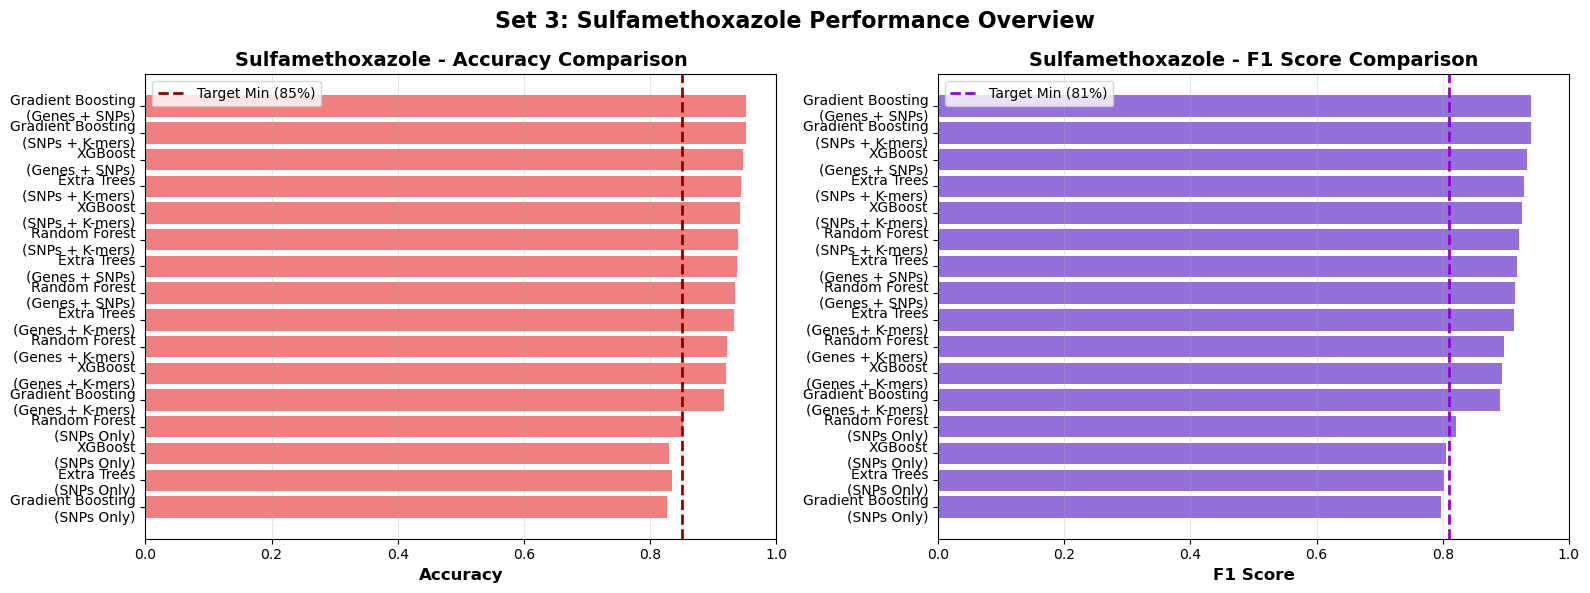

✓ Saved: Sulfamethoxazole_accuracy_f1_comparison.png


In [30]:
# Visualization 2: Side-by-side comparison of Accuracy and F1 Score
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Prepare data
sulfamethoxazole_df['Model_Dataset'] = sulfamethoxazole_df['Model'] + '\n(' + sulfamethoxazole_df['Dataset'] + ')'
sulfamethoxazole_df_plot = sulfamethoxazole_df.sort_values('F1_Score', ascending=True)

# Plot 1: Accuracy
axes[0].barh(sulfamethoxazole_df_plot['Model_Dataset'], sulfamethoxazole_df_plot['Accuracy'], color='lightcoral')
axes[0].set_xlabel('Accuracy', fontsize=12, fontweight='bold')
axes[0].set_title(f'{CONFIG["antibiotic"]} - Accuracy Comparison', fontsize=14, fontweight='bold')
axes[0].set_xlim([0, 1.0])
axes[0].axvline(x=0.85, color='darkred', linestyle='--', linewidth=2, label='Target Min (85%)')
axes[0].grid(axis='x', alpha=0.3)
axes[0].legend()

# Plot 2: F1 Score
axes[1].barh(sulfamethoxazole_df_plot['Model_Dataset'], sulfamethoxazole_df_plot['F1_Score'], color='mediumpurple')
axes[1].set_xlabel('F1 Score', fontsize=12, fontweight='bold')
axes[1].set_title(f'{CONFIG["antibiotic"]} - F1 Score Comparison', fontsize=14, fontweight='bold')
axes[1].set_xlim([0, 1.0])
axes[1].axvline(x=0.81, color='darkviolet', linestyle='--', linewidth=2, label='Target Min (81%)')
axes[1].grid(axis='x', alpha=0.3)
axes[1].legend()

plt.suptitle(f'Set 3: {CONFIG["antibiotic"]} Performance Overview', 
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{CONFIG["antibiotic"]}_accuracy_f1_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"✓ Saved: {CONFIG['antibiotic']}_accuracy_f1_comparison.png")

In [31]:
print("\n" + "="*70)
print("TRAINING FINAL MODEL ON BEST DATASET")
print("="*70)

# Get best dataset and model
best_dataset_name_sulfa = best_sulfa['Dataset']
best_model_name_sulfa = best_sulfa['Model']
best_filepath_sulfa = SULFAMETHOXAZOLE_FILES[best_dataset_name_sulfa]

print(f"Best Dataset: {best_dataset_name_sulfa}")
print(f"Best Model: {best_model_name_sulfa}")
print(f"File: {best_filepath_sulfa}")

# Load the best dataset
X_best_sulfa, y_best_sulfa = load_data_sulfamethoxazole(best_filepath_sulfa, CONFIG['label_column'])

# Calculate scale_pos_weight
scale_pos_weight_sulfa = (y_best_sulfa == 0).sum() / (y_best_sulfa == 1).sum()

# Get the best model
models_sulfa = get_models(scale_pos_weight_sulfa)
final_model_sulfa = models_sulfa[best_model_name_sulfa]

# Train on full dataset
print(f"\nTraining {best_model_name_sulfa} on full {best_dataset_name_sulfa} dataset...")
final_model_sulfa.fit(X_best_sulfa, y_best_sulfa)

print("✓ Final model trained successfully!")
print("\n⚠ Model NOT saved to pickle yet - awaiting your review")
print("="*70)


TRAINING FINAL MODEL ON BEST DATASET
Best Dataset: Genes + SNPs
Best Model: Gradient Boosting
File: Downloads/salmonella_dna/398 files/genes_snps_sulf_labels_398.csv
  ✓ Loaded: 398 samples × 5751 features
    Susceptible (0): 237 (59.5%)
    Resistant (1): 161 (40.5%)

Training Gradient Boosting on full Genes + SNPs dataset...
✓ Final model trained successfully!

⚠ Model NOT saved to pickle yet - awaiting your review



FEATURE IMPORTANCE ANALYSIS

Top 20 Most Important Features:
Rank   Feature                                            Importance  
----------------------------------------------------------------------
1      qacEdelta1                                         0.600531
2      APH(3'')-Ib                                        0.113055
3      NC_003197_2077269_G>T                              0.061647
4      NC_003197_2077267_A>T                              0.061052
5      NC_003197_2077268_T>A                              0.025786
6      NC_003197_1969071_T>C                              0.014441
7      NC_003197_4237990_C>T                              0.010743
8      NC_003197_3669506_G>A                              0.006334
9      dfrA17                                             0.005584
10     mdtB                                               0.005387
11     NC_003197_2002658_C>T                              0.004836
12     NC_003197_3843408_C>T                              0

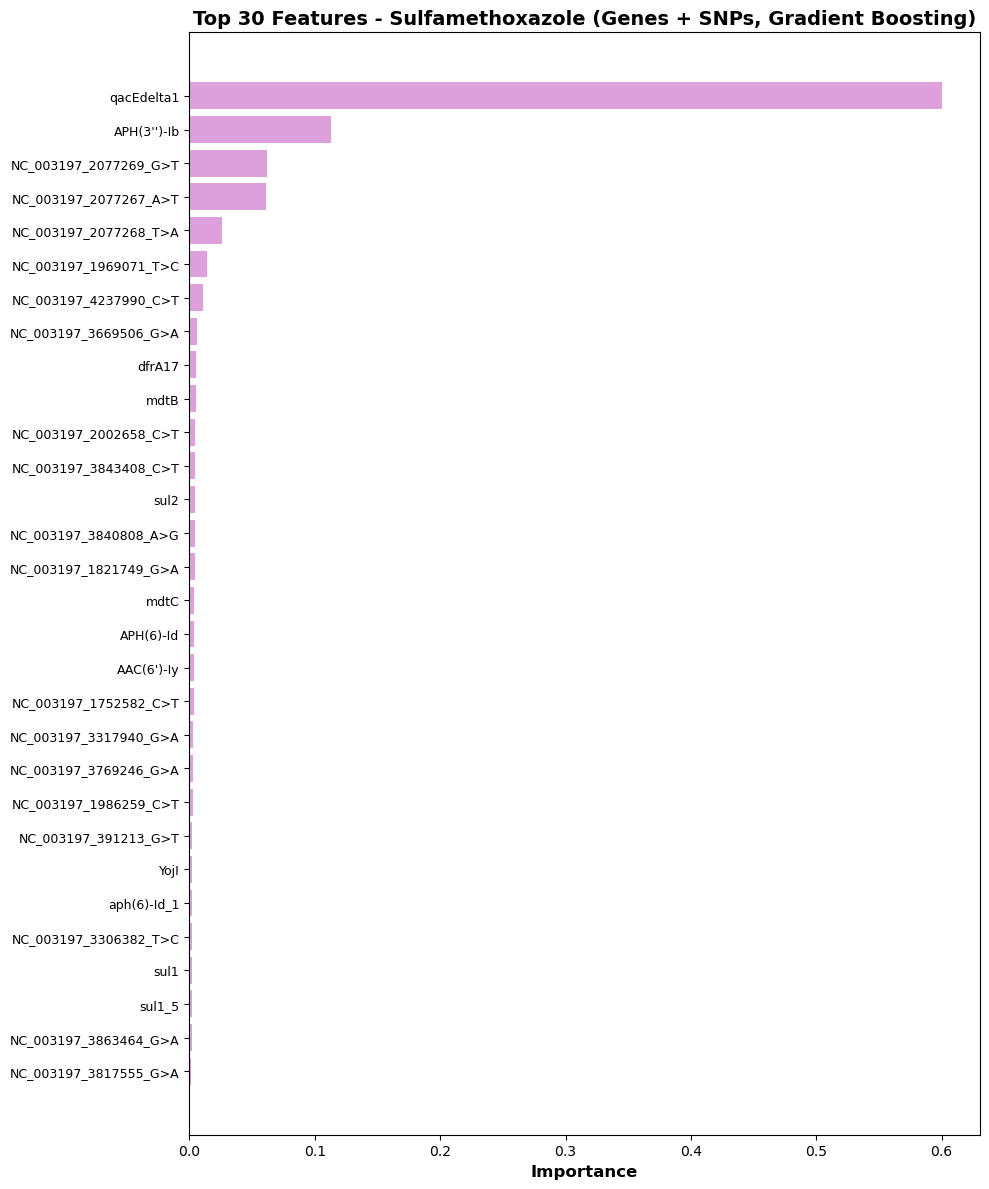


✓ Saved: Sulfamethoxazole_feature_importance.png
✓ Saved: Sulfamethoxazole_feature_importance.csv


In [32]:
# Feature importance (only for tree-based models)
if hasattr(final_model_sulfa, 'feature_importances_'):
    print("\n" + "="*70)
    print("FEATURE IMPORTANCE ANALYSIS")
    print("="*70)
    
    # Get feature names
    feature_names_sulfa = X_best_sulfa.columns.tolist()
    importances_sulfa = final_model_sulfa.feature_importances_
    
    # Sort by importance
    indices_sulfa = np.argsort(importances_sulfa)[::-1]
    
    # Display top 20
    print(f"\nTop 20 Most Important Features:")
    print(f"{'Rank':<6} {'Feature':<50} {'Importance':<12}")
    print("-" * 70)
    
    for i in range(min(20, len(indices_sulfa))):
        idx = indices_sulfa[i]
        print(f"{i+1:<6} {feature_names_sulfa[idx]:<50} {importances_sulfa[idx]:.6f}")
    
    # Visualize top 30
    top_n = 30
    top_indices_sulfa = indices_sulfa[:top_n]
    top_features_sulfa = [feature_names_sulfa[i] for i in top_indices_sulfa]
    top_importances_sulfa = importances_sulfa[top_indices_sulfa]
    
    plt.figure(figsize=(10, 12))
    plt.barh(range(top_n), top_importances_sulfa[::-1], color='plum')
    plt.yticks(range(top_n), top_features_sulfa[::-1], fontsize=9)
    plt.xlabel('Importance', fontweight='bold', fontsize=12)
    plt.title(f'Top {top_n} Features - {CONFIG["antibiotic"]} ({best_dataset_name_sulfa}, {best_model_name_sulfa})', 
              fontweight='bold', fontsize=14)
    plt.tight_layout()
    plt.savefig(f'{CONFIG["antibiotic"]}_feature_importance.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"\n✓ Saved: {CONFIG['antibiotic']}_feature_importance.png")
    
    # Save feature importance to CSV
    importance_df_sulfa = pd.DataFrame({
        'Feature': [feature_names_sulfa[i] for i in indices_sulfa],
        'Importance': importances_sulfa[indices_sulfa]
    })
    importance_df_sulfa.to_csv(f'{CONFIG["antibiotic"]}_feature_importance.csv', index=False)
    print(f"✓ Saved: {CONFIG['antibiotic']}_feature_importance.csv")
    
else:
    print(f"\n⚠ {best_model_name_sulfa} does not support feature importance extraction")

In [33]:
# Final comparison across all three antibiotics
print("\n" + "="*70)
print("COMPLETE CROSS-SET COMPARISON: ALL 3 ANTIBIOTICS")
print("="*70)

print("\n" + "-"*70)
print("Set 1 - Pefoxacin:")
print("-"*70)
print(f"  Best Dataset:  {best_result['Dataset']}")
print(f"  Best Model:    {best_result['Model']}")
print(f"  F1 Score:      {best_result['F1_Score']*100:.2f}%")
print(f"  Accuracy:      {best_result['Accuracy']*100:.2f}%")

print("\n" + "-"*70)
print("Set 2 - Trimethoprim:")
print("-"*70)
print(f"  Best Dataset:  {best_trim['Dataset']}")
print(f"  Best Model:    {best_trim['Model']}")
print(f"  F1 Score:      {best_trim['F1_Score']*100:.2f}%")
print(f"  Accuracy:      {best_trim['Accuracy']*100:.2f}%")

print("\n" + "-"*70)
print("Set 3 - Sulfamethoxazole:")
print("-"*70)
print(f"  Best Dataset:  {best_sulfa['Dataset']}")
print(f"  Best Model:    {best_sulfa['Model']}")
print(f"  F1 Score:      {best_sulfa['F1_Score']*100:.2f}%")
print(f"  Accuracy:      {best_sulfa['Accuracy']*100:.2f}%")

# Analyze consistency
datasets_list = [best_result['Dataset'], best_trim['Dataset'], best_sulfa['Dataset']]
models_list_all = [best_result['Model'], best_trim['Model'], best_sulfa['Model']]

from collections import Counter
dataset_counts = Counter(datasets_list)
model_counts = Counter(models_list_all)

most_common_dataset = dataset_counts.most_common(1)[0]
most_common_model = model_counts.most_common(1)[0]

print("\n" + "="*70)
print("CONSISTENCY ANALYSIS")
print("="*70)
print(f"Most frequent best dataset: {most_common_dataset[0]} ({most_common_dataset[1]}/3 times)")
print(f"Most frequent best model:   {most_common_model[0]} ({most_common_model[1]}/3 times)")

if most_common_dataset[1] == 3:
    print(f"\n✓ CONSISTENT: {most_common_dataset[0]} was best for ALL antibiotics!")
elif most_common_dataset[1] == 2:
    print(f"\n⚠ PARTIALLY CONSISTENT: {most_common_dataset[0]} was best for 2/3 antibiotics")
else:
    print(f"\n✗ INCONSISTENT: Different datasets performed best for each antibiotic")

print("="*70)


COMPLETE CROSS-SET COMPARISON: ALL 3 ANTIBIOTICS

----------------------------------------------------------------------
Set 1 - Pefoxacin:
----------------------------------------------------------------------
  Best Dataset:  SNPs + K-mers
  Best Model:    Gradient Boosting
  F1 Score:      85.05%
  Accuracy:      92.70%

----------------------------------------------------------------------
Set 2 - Trimethoprim:
----------------------------------------------------------------------
  Best Dataset:  SNPs + K-mers
  Best Model:    Extra Trees
  F1 Score:      95.03%
  Accuracy:      95.48%

----------------------------------------------------------------------
Set 3 - Sulfamethoxazole:
----------------------------------------------------------------------
  Best Dataset:  Genes + SNPs
  Best Model:    Gradient Boosting
  F1 Score:      94.05%
  Accuracy:      95.21%

CONSISTENCY ANALYSIS
Most frequent best dataset: SNPs + K-mers (2/3 times)
Most frequent best model:   Gradient Boosti

# SUMMARY

In [34]:
# Combine all results into one master dataframe
master_results_df = pd.concat([
    results_df,  # Set 1: Pefoxacin
    trimethoprim_df,  # Set 2: Trimethoprim
    sulfamethoxazole_df  # Set 3: Sulfamethoxazole
], ignore_index=True)

# Save master summary
master_results_df.to_csv('Master_Training_Summary_All_Antibiotics.csv', index=False)
print("\n✓ Saved: Master_Training_Summary_All_Antibiotics.csv")

# Display overall best performers
print("\n" + "="*70)
print("TOP 5 OVERALL BEST PERFORMERS (All Antibiotics)")
print("="*70)
top_5_overall = master_results_df.sort_values('F1_Score', ascending=False).head(5)
print(top_5_overall.to_string(index=False))
print("="*70)


✓ Saved: Master_Training_Summary_All_Antibiotics.csv

TOP 5 OVERALL BEST PERFORMERS (All Antibiotics)
  Antibiotic       Dataset         Model  Accuracy  Precision   Recall  F1_Score                  Model_Dataset
Trimethoprim SNPs + K-mers   Extra Trees  0.954809   0.972520 0.930276  0.950331   Extra Trees\n(SNPs + K-mers)
Trimethoprim SNPs + K-mers Random Forest  0.952322   0.972137 0.924899  0.947325 Random Forest\n(SNPs + K-mers)
Trimethoprim  Genes + SNPs Random Forest  0.952359   0.982540 0.914483  0.946969  Random Forest\n(Genes + SNPs)
Trimethoprim SNPs + K-mers       XGBoost  0.949834   0.971969 0.919691  0.944401       XGBoost\n(SNPs + K-mers)
Trimethoprim  Genes + SNPs   Extra Trees  0.949796   0.977316 0.914483  0.944219    Extra Trees\n(Genes + SNPs)


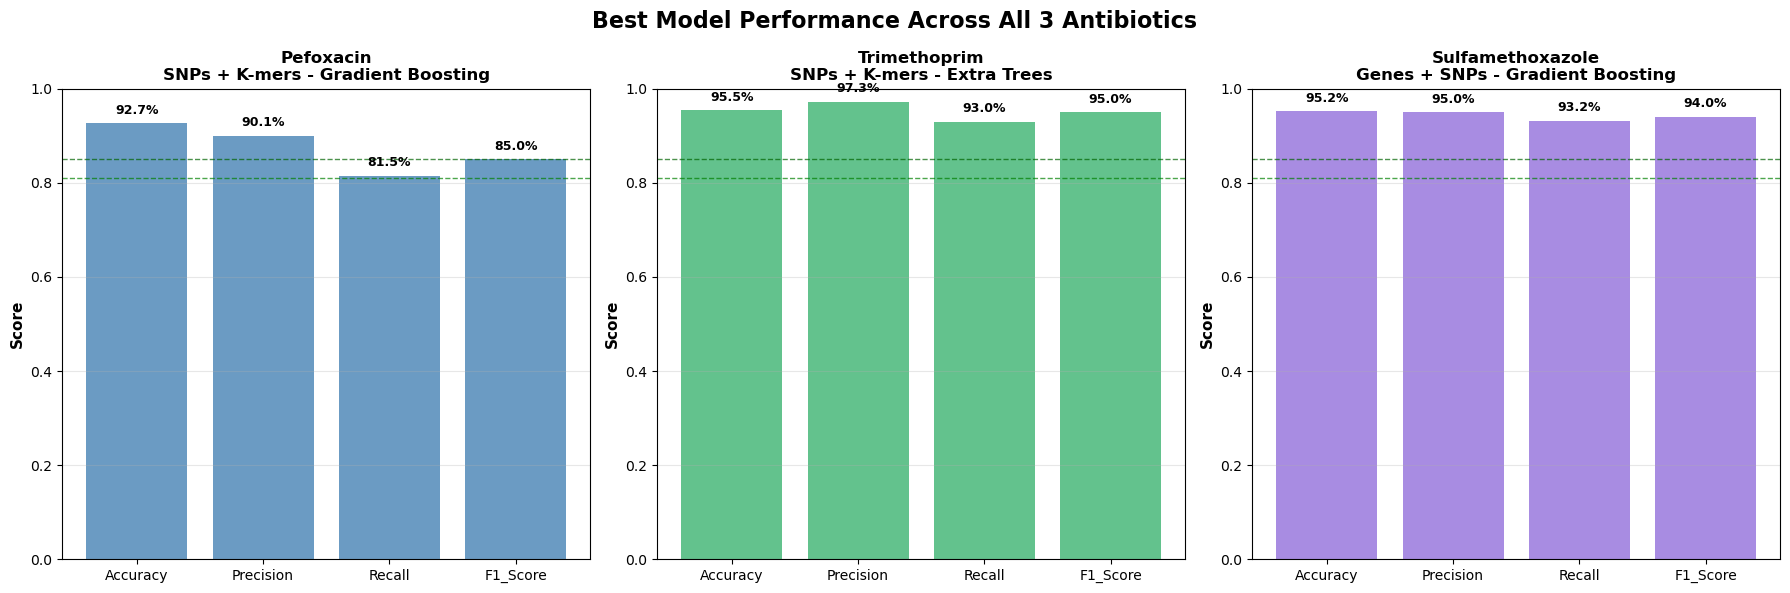

✓ Saved: Cross_Antibiotic_Best_Performance.png


In [35]:
# Create comprehensive comparison visualization
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

antibiotics = ['Pefoxacin', 'Trimethoprim', 'Sulfamethoxazole']
best_results = [best_result, best_trim, best_sulfa]
colors = ['steelblue', 'mediumseagreen', 'mediumpurple']

for idx, (antibiotic, best, color) in enumerate(zip(antibiotics, best_results, colors)):
    # Extract metrics
    metrics = ['Accuracy', 'Precision', 'Recall', 'F1_Score']
    values = [best[m] for m in metrics]
    
    # Plot
    axes[idx].bar(metrics, values, color=color, alpha=0.8)
    axes[idx].set_ylim([0, 1.0])
    axes[idx].set_ylabel('Score', fontsize=11, fontweight='bold')
    axes[idx].set_title(f'{antibiotic}\n{best["Dataset"]} - {best["Model"]}', 
                       fontsize=12, fontweight='bold')
    axes[idx].axhline(y=0.81, color='green', linestyle='--', linewidth=1, alpha=0.7)
    axes[idx].axhline(y=0.85, color='darkgreen', linestyle='--', linewidth=1, alpha=0.7)
    axes[idx].grid(axis='y', alpha=0.3)
    
    # Add value labels
    for j, (metric, value) in enumerate(zip(metrics, values)):
        axes[idx].text(j, value + 0.02, f'{value*100:.1f}%', ha='center', fontsize=9, fontweight='bold')

plt.suptitle('Best Model Performance Across All 3 Antibiotics', 
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('Cross_Antibiotic_Best_Performance.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Saved: Cross_Antibiotic_Best_Performance.png")

In [36]:
print("\n" + "="*70)
print("COMPLETE PROJECT SUMMARY")
print("="*70)
print(f"\nTotal models trained: {len(master_results_df)}")
print(f"Total antibiotics tested: 3")
print(f"Dataset variants per antibiotic: 4")
print(f"ML algorithms tested: 4")
print(f"Cross-validation folds: {CONFIG['n_folds']}")

print("\n" + "-"*70)
print("FILES GENERATED:")
print("-"*70)
print("CSV Files:")
print("  - Pefoxacin_training_summary.csv")
print("  - Trimethoprim_training_summary.csv")
print("  - Sulfamethoxazole_training_summary.csv")
print("  - Master_Training_Summary_All_Antibiotics.csv")
print("  - Pefoxacin_feature_importance.csv (if applicable)")
print("  - Trimethoprim_feature_importance.csv (if applicable)")
print("  - Sulfamethoxazole_feature_importance.csv (if applicable)")

print("\nVisualization Files:")
print("  - Pefoxacin_dataset_comparison.png")
print("  - Pefoxacin_accuracy_f1_comparison.png")
print("  - Pefoxacin_feature_importance.png (if applicable)")
print("  - Trimethoprim_dataset_comparison.png")
print("  - Trimethoprim_accuracy_f1_comparison.png")
print("  - Trimethoprim_feature_importance.png (if applicable)")
print("  - Sulfamethoxazole_dataset_comparison.png")
print("  - Sulfamethoxazole_accuracy_f1_comparison.png")
print("  - Sulfamethoxazole_feature_importance.png (if applicable)")
print("  - Cross_Antibiotic_Best_Performance.png")

print("\n" + "="*70)
print("✓ ALL TRAINING COMPLETE - MODELS READY FOR REVIEW")
print("="*70)


COMPLETE PROJECT SUMMARY

Total models trained: 48
Total antibiotics tested: 3
Dataset variants per antibiotic: 4
ML algorithms tested: 4
Cross-validation folds: 6

----------------------------------------------------------------------
FILES GENERATED:
----------------------------------------------------------------------
CSV Files:
  - Pefoxacin_training_summary.csv
  - Trimethoprim_training_summary.csv
  - Sulfamethoxazole_training_summary.csv
  - Master_Training_Summary_All_Antibiotics.csv
  - Pefoxacin_feature_importance.csv (if applicable)
  - Trimethoprim_feature_importance.csv (if applicable)
  - Sulfamethoxazole_feature_importance.csv (if applicable)

Visualization Files:
  - Pefoxacin_dataset_comparison.png
  - Pefoxacin_accuracy_f1_comparison.png
  - Pefoxacin_feature_importance.png (if applicable)
  - Trimethoprim_dataset_comparison.png
  - Trimethoprim_accuracy_f1_comparison.png
  - Trimethoprim_feature_importance.png (if applicable)
  - Sulfamethoxazole_dataset_comparison

# TRAINING ON THE FULL MATRIX ---- SET 4

## PEFLOXACIN 

In [37]:
# File path for full Pefoxacin dataset (merged)
PEFOXACIN_FULL_FILE = 'Downloads/salmonella_dna/398 files/final_pefloxain_dataset_398.csv'

# Update configuration for Set 4
CONFIG['antibiotic'] = 'Pefoxacin'
CONFIG['label_column'] = 'Pefloxacin_Phenotype'
CONFIG['dataset_type'] = 'Complete (Genes + K-mers + SNPs)'

print("\n" + "="*70)
print(f"SET 4: {CONFIG['antibiotic']} - Full Dataset Training")
print("="*70)
print(f"Dataset type: {CONFIG['dataset_type']}")
print(f"Cross-validation folds: {CONFIG['n_folds']}")
print("="*70)


SET 4: Pefoxacin - Full Dataset Training
Dataset type: Complete (Genes + K-mers + SNPs)
Cross-validation folds: 6


In [38]:
def load_full_data(filepath, label_column):
    """Load complete merged dataset"""
    df = pd.read_csv(filepath)
    
    # Remove Genome_ID and label column to get features
    X = df.drop(columns=['Genome_ID', label_column])
    y = df[label_column]
    
    # Validate
    assert len(X) == len(y), "Mismatch in samples"
    assert y.isin([0, 1]).all(), "Labels must be 0 (susceptible) or 1 (resistant)"
    
    print(f"  ✓ Loaded: {len(X)} samples × {X.shape[1]} features")
    print(f"    Susceptible (0): {(y==0).sum()} ({(y==0).sum()/len(y)*100:.1f}%)")
    print(f"    Resistant (1): {(y==1).sum()} ({(y==1).sum()/len(y)*100:.1f}%)")
    
    return X, y

print("✓ Full dataset loader ready")

✓ Full dataset loader ready


In [39]:
# Storage for full dataset results
pefoxacin_full_results = []

print("\n" + "="*70)
print(f"TRAINING MODELS FOR SET 4: {CONFIG['antibiotic']}")
print("="*70)
print(f"Dataset: {CONFIG['dataset_type']}")
print(f"File: {PEFOXACIN_FULL_FILE}")
print("="*70)

# Load data
X_full, y_full = load_full_data(PEFOXACIN_FULL_FILE, CONFIG['label_column'])

# Calculate class weight for XGBoost
n_susceptible = (y_full == 0).sum()
n_resistant = (y_full == 1).sum()
scale_pos_weight = n_susceptible / n_resistant if n_resistant > 0 else 1.0

print(f"  Class imbalance ratio: {scale_pos_weight:.2f}")

# Get models
models = get_models(scale_pos_weight)

# Train each model
for model_name, model in models.items():
    print(f"\n  Training: {model_name}...")
    
    # Cross-validation
    metrics = evaluate_model_cv(X_full, y_full, model, n_folds=CONFIG['n_folds'])
    
    # Store results
    pefoxacin_full_results.append({
        'Antibiotic': CONFIG['antibiotic'],
        'Dataset': CONFIG['dataset_type'],
        'Model': model_name,
        'Accuracy': metrics['accuracy'],
        'Precision': metrics['precision'],
        'Recall': metrics['recall'],
        'F1_Score': metrics['f1']
    })
    
    print(f"    ✓ Accuracy:  {metrics['accuracy']*100:.2f}%")
    print(f"    ✓ Precision: {metrics['precision']*100:.2f}%")
    print(f"    ✓ Recall:    {metrics['recall']*100:.2f}%")
    print(f"    ✓ F1 Score:  {metrics['f1']*100:.2f}%")

print("\n" + "="*70)
print("✓ TRAINING COMPLETE FOR SET 4")
print("="*70)


TRAINING MODELS FOR SET 4: Pefoxacin
Dataset: Complete (Genes + K-mers + SNPs)
File: Downloads/salmonella_dna/398 files/final_pefloxain_dataset_398.csv
  ✓ Loaded: 398 samples × 10800 features
    Susceptible (0): 295 (74.1%)
    Resistant (1): 103 (25.9%)
  Class imbalance ratio: 2.86

  Training: Random Forest...
    ✓ Accuracy:  92.20%
    ✓ Precision: 91.27%
    ✓ Recall:    78.49%
    ✓ F1 Score:  83.56%

  Training: Extra Trees...
    ✓ Accuracy:  91.69%
    ✓ Precision: 89.31%
    ✓ Recall:    78.49%
    ✓ F1 Score:  82.65%

  Training: Gradient Boosting...
    ✓ Accuracy:  93.46%
    ✓ Precision: 91.96%
    ✓ Recall:    82.41%
    ✓ F1 Score:  86.55%

  Training: XGBoost...
    ✓ Accuracy:  91.69%
    ✓ Precision: 81.81%
    ✓ Recall:    88.24%
    ✓ F1 Score:  84.66%

✓ TRAINING COMPLETE FOR SET 4


In [40]:
# Create DataFrame
pefoxacin_full_df = pd.DataFrame(pefoxacin_full_results)
pefoxacin_full_df_sorted = pefoxacin_full_df.sort_values('F1_Score', ascending=False)

print("\n" + "="*70)
print(f"SUMMARY RESULTS - SET 4: {CONFIG['antibiotic']}")
print("="*70)
print(pefoxacin_full_df_sorted.to_string(index=False))
print("="*70)

# Save to CSV
output_filename = f'{CONFIG["antibiotic"]}_training_summary.csv'
pefoxacin_full_df.to_csv(output_filename, index=False)
print(f"\n✓ Results saved to: {output_filename}")

# Best model
best_pefox_full = pefoxacin_full_df_sorted.iloc[0]

print("\n" + "="*70)
print("BEST PERFORMING MODEL - FULL DATASET")
print("="*70)
print(f"Model: {best_pefox_full['Model']}")
print(f"Accuracy: {best_pefox_full['Accuracy']*100:.2f}%")
print(f"Precision: {best_pefox_full['Precision']*100:.2f}%")
print(f"Recall: {best_pefox_full['Recall']*100:.2f}%")
print(f"F1 Score: {best_pefox_full['F1_Score']*100:.2f}%")
print("="*70)

# Check targets
meets_f1_target = 0.81 <= best_pefox_full['F1_Score'] <= 0.99
meets_acc_target = 0.85 <= best_pefox_full['Accuracy'] <= 0.99

print(f"\n{'='*70}")
print("TARGET METRICS EVALUATION")
print("="*70)
print(f"F1 Score Target (81-99%): {'✓ PASS' if meets_f1_target else '✗ FAIL'}")
print(f"Accuracy Target (85-99%): {'✓ PASS' if meets_acc_target else '✗ FAIL'}")
print("="*70)


SUMMARY RESULTS - SET 4: Pefoxacin
Antibiotic                          Dataset             Model  Accuracy  Precision   Recall  F1_Score
 Pefoxacin Complete (Genes + K-mers + SNPs) Gradient Boosting  0.934570   0.919612 0.824074  0.865473
 Pefoxacin Complete (Genes + K-mers + SNPs)           XGBoost  0.916930   0.818122 0.882353  0.846633
 Pefoxacin Complete (Genes + K-mers + SNPs)     Random Forest  0.922019   0.912681 0.784858  0.835587
 Pefoxacin Complete (Genes + K-mers + SNPs)       Extra Trees  0.916893   0.893137 0.784858  0.826505

✓ Results saved to: Pefoxacin_training_summary.csv

BEST PERFORMING MODEL - FULL DATASET
Model: Gradient Boosting
Accuracy: 93.46%
Precision: 91.96%
Recall: 82.41%
F1 Score: 86.55%

TARGET METRICS EVALUATION
F1 Score Target (81-99%): ✓ PASS
Accuracy Target (85-99%): ✓ PASS


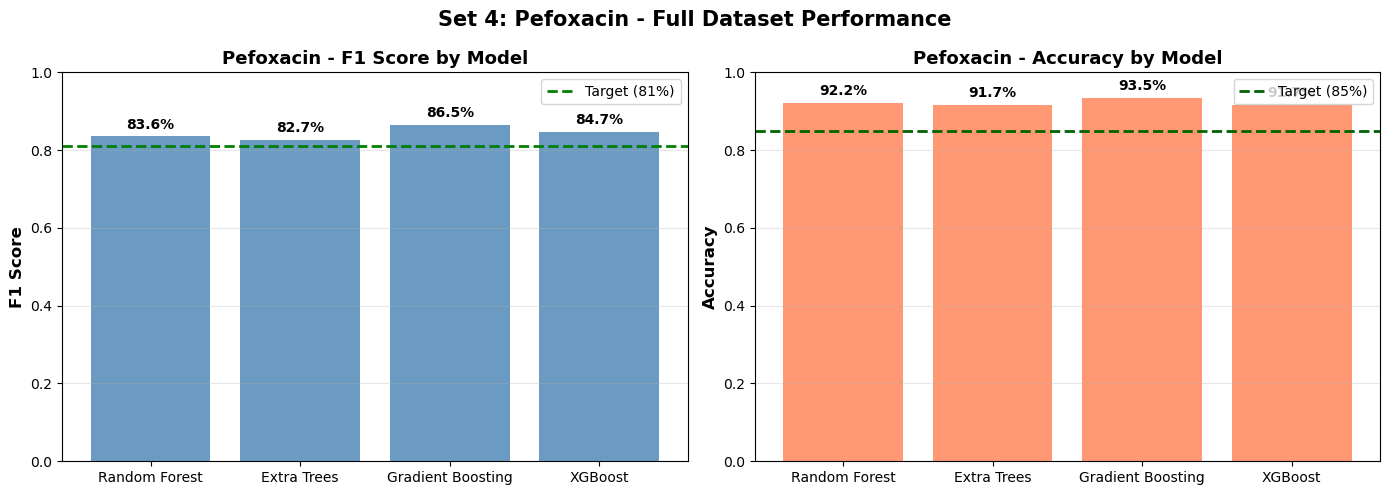

✓ Saved: Pefoxacin_model_comparison.png


In [41]:
# Visualization: Compare all models on full dataset
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

models_list = pefoxacin_full_df['Model'].tolist()
f1_scores = pefoxacin_full_df['F1_Score'].tolist()
accuracies = pefoxacin_full_df['Accuracy'].tolist()

# Plot 1: F1 Scores
axes[0].bar(models_list, f1_scores, color='steelblue', alpha=0.8)
axes[0].set_ylabel('F1 Score', fontsize=12, fontweight='bold')
axes[0].set_title(f'{CONFIG["antibiotic"]} - F1 Score by Model', fontsize=13, fontweight='bold')
axes[0].set_ylim([0, 1.0])
axes[0].axhline(y=0.81, color='green', linestyle='--', linewidth=2, label='Target (81%)')
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)
for i, (model, score) in enumerate(zip(models_list, f1_scores)):
    axes[0].text(i, score + 0.02, f'{score*100:.1f}%', ha='center', fontsize=10, fontweight='bold')

# Plot 2: Accuracy
axes[1].bar(models_list, accuracies, color='coral', alpha=0.8)
axes[1].set_ylabel('Accuracy', fontsize=12, fontweight='bold')
axes[1].set_title(f'{CONFIG["antibiotic"]} - Accuracy by Model', fontsize=13, fontweight='bold')
axes[1].set_ylim([0, 1.0])
axes[1].axhline(y=0.85, color='darkgreen', linestyle='--', linewidth=2, label='Target (85%)')
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)
for i, (model, score) in enumerate(zip(models_list, accuracies)):
    axes[1].text(i, score + 0.02, f'{score*100:.1f}%', ha='center', fontsize=10, fontweight='bold')

plt.suptitle(f'Set 4: {CONFIG["antibiotic"]} - Full Dataset Performance', 
             fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{CONFIG["antibiotic"]}_model_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"✓ Saved: {CONFIG['antibiotic']}_model_comparison.png")


TRAINING FINAL MODEL ON FULL DATASET
Training Gradient Boosting on complete dataset...
✓ Final model trained successfully!

⚠ Model NOT saved to pickle yet - awaiting your review

FEATURE IMPORTANCE ANALYSIS - FULL DATASET

Top 20 Most Important Features:
Rank   Feature                                            Importance  
----------------------------------------------------------------------
1      NC_003197_3437381_A>T                              0.229406
2      AMYDKLEGLG                                         0.099253
3      AQAMYDKLEG                                         0.079262
4      AQAMWDAAQR                                         0.079250
5      YNPNAQAMYD                                         0.070467
6      NPNAQAMYDK                                         0.041843
7      QAMYDKLEGL                                         0.040842
8      VLFHEAQAMW                                         0.033986
9      NC_003197_3709210_C>T                              0.02817

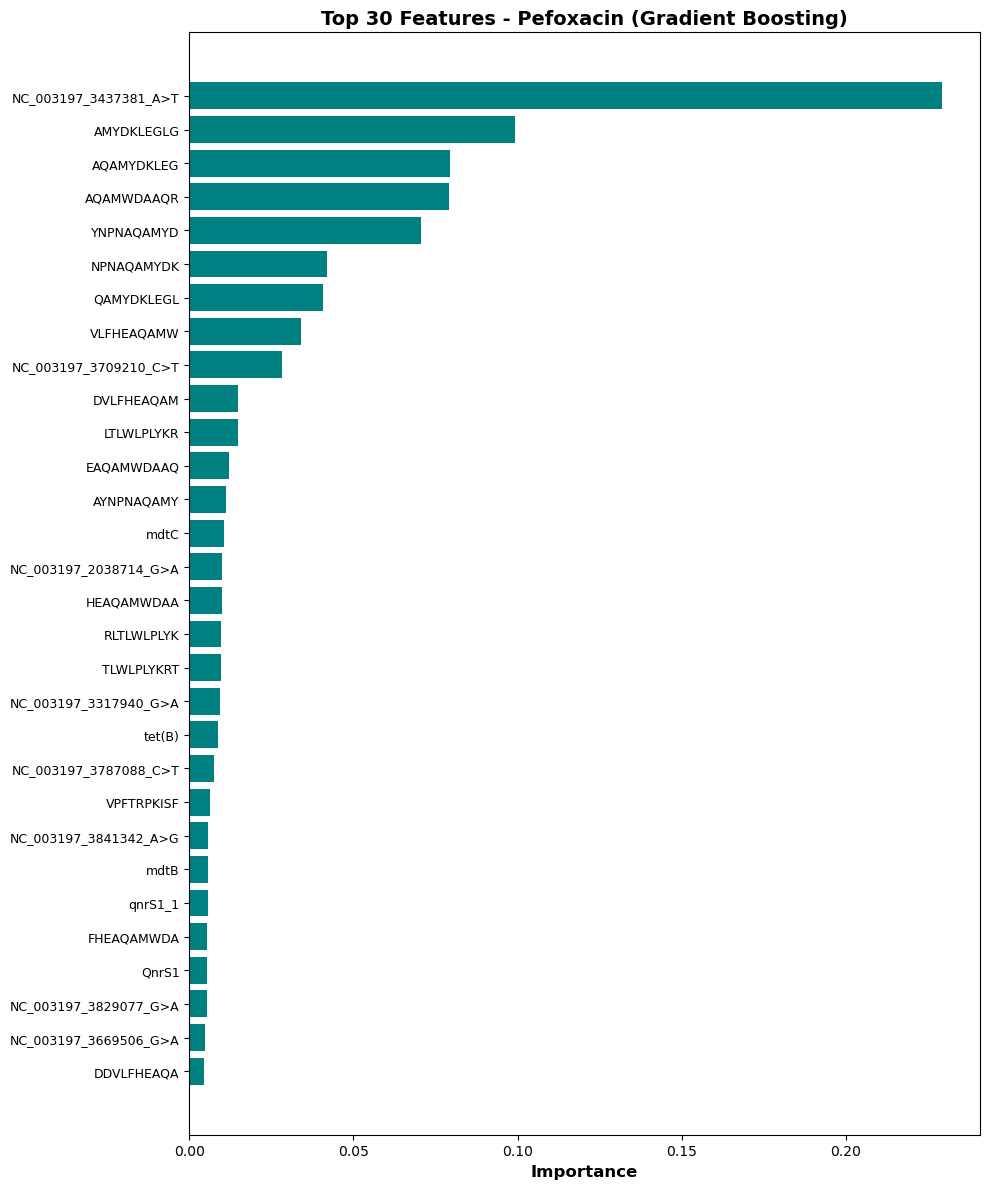


✓ Saved: Pefoxacin_feature_importance.png
✓ Saved: Pefoxacin_feature_importance.csv


In [42]:
print("\n" + "="*70)
print("TRAINING FINAL MODEL ON FULL DATASET")
print("="*70)

best_model_name_pefox_full = best_pefox_full['Model']

# Get the best model
models_pefox_full = get_models(scale_pos_weight)
final_model_pefox_full = models_pefox_full[best_model_name_pefox_full]

# Train on full dataset
print(f"Training {best_model_name_pefox_full} on complete dataset...")
final_model_pefox_full.fit(X_full, y_full)

print("✓ Final model trained successfully!")
print("\n⚠ Model NOT saved to pickle yet - awaiting your review")
print("="*70)

# Feature importance (if applicable)
if hasattr(final_model_pefox_full, 'feature_importances_'):
    print("\n" + "="*70)
    print("FEATURE IMPORTANCE ANALYSIS - FULL DATASET")
    print("="*70)
    
    feature_names_full = X_full.columns.tolist()
    importances_full = final_model_pefox_full.feature_importances_
    indices_full = np.argsort(importances_full)[::-1]
    
    # Display top 20
    print(f"\nTop 20 Most Important Features:")
    print(f"{'Rank':<6} {'Feature':<50} {'Importance':<12}")
    print("-" * 70)
    
    for i in range(min(20, len(indices_full))):
        idx = indices_full[i]
        print(f"{i+1:<6} {feature_names_full[idx]:<50} {importances_full[idx]:.6f}")
    
    # Visualize top 30
    top_n = 30
    top_indices_full = indices_full[:top_n]
    top_features_full = [feature_names_full[i] for i in top_indices_full]
    top_importances_full = importances_full[top_indices_full]
    
    plt.figure(figsize=(10, 12))
    plt.barh(range(top_n), top_importances_full[::-1], color='teal')
    plt.yticks(range(top_n), top_features_full[::-1], fontsize=9)
    plt.xlabel('Importance', fontweight='bold', fontsize=12)
    plt.title(f'Top {top_n} Features - {CONFIG["antibiotic"]} ({best_model_name_pefox_full})', 
              fontweight='bold', fontsize=14)
    plt.tight_layout()
    plt.savefig(f'{CONFIG["antibiotic"]}_feature_importance.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"\n✓ Saved: {CONFIG['antibiotic']}_feature_importance.png")
    
    # Save to CSV
    importance_df_full = pd.DataFrame({
        'Feature': [feature_names_full[i] for i in indices_full],
        'Importance': importances_full[indices_full]
    })
    importance_df_full.to_csv(f'{CONFIG["antibiotic"]}_feature_importance.csv', index=False)
    print(f"✓ Saved: {CONFIG['antibiotic']}_feature_importance.csv")

# SET 5 - TRIMETHROPIN FULL DATASET

In [43]:
# File path for full Trimethoprim dataset (merged)
TRIMETHOPRIM_FULL_FILE = 'Downloads/salmonella_dna/398 files/final_trim_dataset_398.csv'

# Update configuration for Set 5
CONFIG['antibiotic'] = 'Trimethoprim_Full'
CONFIG['label_column'] = 'Label'
CONFIG['dataset_type'] = 'Complete (Genes + K-mers + SNPs)'

print("\n" + "="*70)
print(f"SET 5: {CONFIG['antibiotic']} - Full Dataset Training")
print("="*70)
print(f"Dataset type: {CONFIG['dataset_type']}")
print(f"Cross-validation folds: {CONFIG['n_folds']}")
print("="*70)


SET 5: Trimethoprim_Full - Full Dataset Training
Dataset type: Complete (Genes + K-mers + SNPs)
Cross-validation folds: 6


In [44]:
# Storage for full dataset results
trimethoprim_full_results = []

print("\n" + "="*70)
print(f"TRAINING MODELS FOR SET 5: {CONFIG['antibiotic']}")
print("="*70)

# Load data
X_trim_full, y_trim_full = load_full_data(TRIMETHOPRIM_FULL_FILE, CONFIG['label_column'])

# Calculate class weight
scale_pos_weight_trim = (y_trim_full == 0).sum() / (y_trim_full == 1).sum()
print(f"  Class imbalance ratio: {scale_pos_weight_trim:.2f}")

# Get models
models_trim = get_models(scale_pos_weight_trim)

# Train each model
for model_name, model in models_trim.items():
    print(f"\n  Training: {model_name}...")
    
    metrics = evaluate_model_cv(X_trim_full, y_trim_full, model, n_folds=CONFIG['n_folds'])
    
    trimethoprim_full_results.append({
        'Antibiotic': CONFIG['antibiotic'],
        'Dataset': CONFIG['dataset_type'],
        'Model': model_name,
        'Accuracy': metrics['accuracy'],
        'Precision': metrics['precision'],
        'Recall': metrics['recall'],
        'F1_Score': metrics['f1']
    })
    
    print(f"    ✓ Accuracy:  {metrics['accuracy']*100:.2f}%")
    print(f"    ✓ Precision: {metrics['precision']*100:.2f}%")
    print(f"    ✓ Recall:    {metrics['recall']*100:.2f}%")
    print(f"    ✓ F1 Score:  {metrics['f1']*100:.2f}%")

print("\n" + "="*70)
print("✓ TRAINING COMPLETE FOR SET 5")
print("="*70)


TRAINING MODELS FOR SET 5: Trimethoprim_Full
  ✓ Loaded: 398 samples × 10800 features
    Susceptible (0): 211 (53.0%)
    Resistant (1): 187 (47.0%)
  Class imbalance ratio: 1.13

  Training: Random Forest...
    ✓ Accuracy:  94.21%
    ✓ Precision: 96.61%
    ✓ Recall:    90.88%
    ✓ F1 Score:  93.58%

  Training: Extra Trees...
    ✓ Accuracy:  94.72%
    ✓ Precision: 96.66%
    ✓ Recall:    91.95%
    ✓ F1 Score:  94.18%

  Training: Gradient Boosting...
    ✓ Accuracy:  94.72%
    ✓ Precision: 94.89%
    ✓ Recall:    94.10%
    ✓ F1 Score:  94.35%

  Training: XGBoost...
    ✓ Accuracy:  94.71%
    ✓ Precision: 97.15%
    ✓ Recall:    91.41%
    ✓ F1 Score:  94.12%

✓ TRAINING COMPLETE FOR SET 5


In [45]:
# Create DataFrame
trimethoprim_full_df = pd.DataFrame(trimethoprim_full_results)
trimethoprim_full_df_sorted = trimethoprim_full_df.sort_values('F1_Score', ascending=False)

print("\n" + "="*70)
print(f"SUMMARY RESULTS - SET 5: {CONFIG['antibiotic']}")
print("="*70)
print(trimethoprim_full_df_sorted.to_string(index=False))
print("="*70)

# Save to CSV
output_filename = f'{CONFIG["antibiotic"]}_training_summary.csv'
trimethoprim_full_df.to_csv(output_filename, index=False)
print(f"\n✓ Results saved to: {output_filename}")

# Best model
best_trim_full = trimethoprim_full_df_sorted.iloc[0]

print("\n" + "="*70)
print("BEST PERFORMING MODEL - FULL DATASET")
print("="*70)
print(f"Model: {best_trim_full['Model']}")
print(f"Accuracy: {best_trim_full['Accuracy']*100:.2f}%")
print(f"Precision: {best_trim_full['Precision']*100:.2f}%")
print(f"Recall: {best_trim_full['Recall']*100:.2f}%")
print(f"F1 Score: {best_trim_full['F1_Score']*100:.2f}%")
print("="*70)

# Check targets
meets_f1_target = 0.81 <= best_trim_full['F1_Score'] <= 0.99
meets_acc_target = 0.85 <= best_trim_full['Accuracy'] <= 0.99

print(f"\n{'='*70}")
print("TARGET METRICS EVALUATION")
print("="*70)
print(f"F1 Score Target (81-99%): {'✓ PASS' if meets_f1_target else '✗ FAIL'}")
print(f"Accuracy Target (85-99%): {'✓ PASS' if meets_acc_target else '✗ FAIL'}")
print("="*70)


SUMMARY RESULTS - SET 5: Trimethoprim_Full
       Antibiotic                          Dataset             Model  Accuracy  Precision   Recall  F1_Score
Trimethoprim_Full Complete (Genes + K-mers + SNPs) Gradient Boosting  0.947196   0.948927 0.941028  0.943475
Trimethoprim_Full Complete (Genes + K-mers + SNPs)       Extra Trees  0.947158   0.966579 0.919523  0.941842
Trimethoprim_Full Complete (Genes + K-mers + SNPs)           XGBoost  0.947120   0.971514 0.914147  0.941180
Trimethoprim_Full Complete (Genes + K-mers + SNPs)     Random Forest  0.942108   0.966138 0.908770  0.935804

✓ Results saved to: Trimethoprim_Full_training_summary.csv

BEST PERFORMING MODEL - FULL DATASET
Model: Gradient Boosting
Accuracy: 94.72%
Precision: 94.89%
Recall: 94.10%
F1 Score: 94.35%

TARGET METRICS EVALUATION
F1 Score Target (81-99%): ✓ PASS
Accuracy Target (85-99%): ✓ PASS


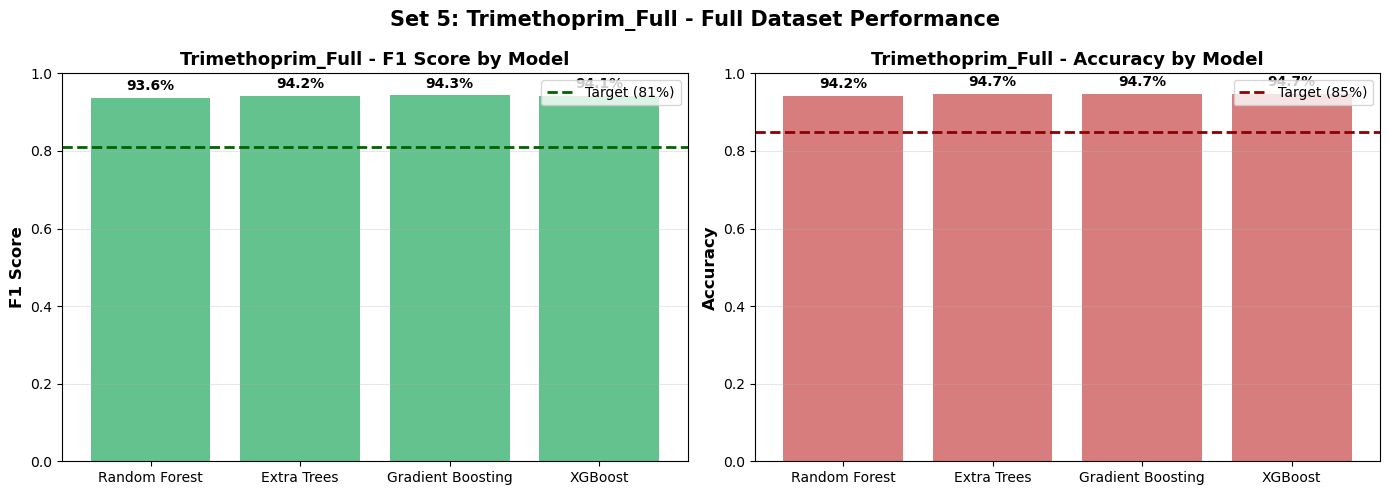

✓ Saved: Trimethoprim_Full_model_comparison.png


In [46]:
# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

models_list = trimethoprim_full_df['Model'].tolist()
f1_scores = trimethoprim_full_df['F1_Score'].tolist()
accuracies = trimethoprim_full_df['Accuracy'].tolist()

# Plot 1: F1 Scores
axes[0].bar(models_list, f1_scores, color='mediumseagreen', alpha=0.8)
axes[0].set_ylabel('F1 Score', fontsize=12, fontweight='bold')
axes[0].set_title(f'{CONFIG["antibiotic"]} - F1 Score by Model', fontsize=13, fontweight='bold')
axes[0].set_ylim([0, 1.0])
axes[0].axhline(y=0.81, color='darkgreen', linestyle='--', linewidth=2, label='Target (81%)')
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)
for i, (model, score) in enumerate(zip(models_list, f1_scores)):
    axes[0].text(i, score + 0.02, f'{score*100:.1f}%', ha='center', fontsize=10, fontweight='bold')

# Plot 2: Accuracy
axes[1].bar(models_list, accuracies, color='indianred', alpha=0.8)
axes[1].set_ylabel('Accuracy', fontsize=12, fontweight='bold')
axes[1].set_title(f'{CONFIG["antibiotic"]} - Accuracy by Model', fontsize=13, fontweight='bold')
axes[1].set_ylim([0, 1.0])
axes[1].axhline(y=0.85, color='darkred', linestyle='--', linewidth=2, label='Target (85%)')
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)
for i, (model, score) in enumerate(zip(models_list, accuracies)):
    axes[1].text(i, score + 0.02, f'{score*100:.1f}%', ha='center', fontsize=10, fontweight='bold')

plt.suptitle(f'Set 5: {CONFIG["antibiotic"]} - Full Dataset Performance', 
             fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{CONFIG["antibiotic"]}_model_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"✓ Saved: {CONFIG['antibiotic']}_model_comparison.png")


TRAINING FINAL MODEL ON FULL DATASET
Training Gradient Boosting on complete dataset...
✓ Final model trained successfully!

⚠ Model NOT saved to pickle yet - awaiting your review

FEATURE IMPORTANCE ANALYSIS - FULL DATASET

Top 20 Most Important Features:
Rank   Feature                                            Importance  
----------------------------------------------------------------------
1      DSYQPATQAY                                         0.153924
2      FYPQLAKSSA                                         0.114643
3      KSSAKLVVMH                                         0.093122
4      NC_003197_4039892_G>A                              0.081438
5      SSAKLVVMHS                                         0.075642
6      SAKLVVMHSV                                         0.072398
7      GFPDAAFYPQ                                         0.061557
8      SYQPATQAYA                                         0.050679
9      IRGFPDAAFY                                         0.03329

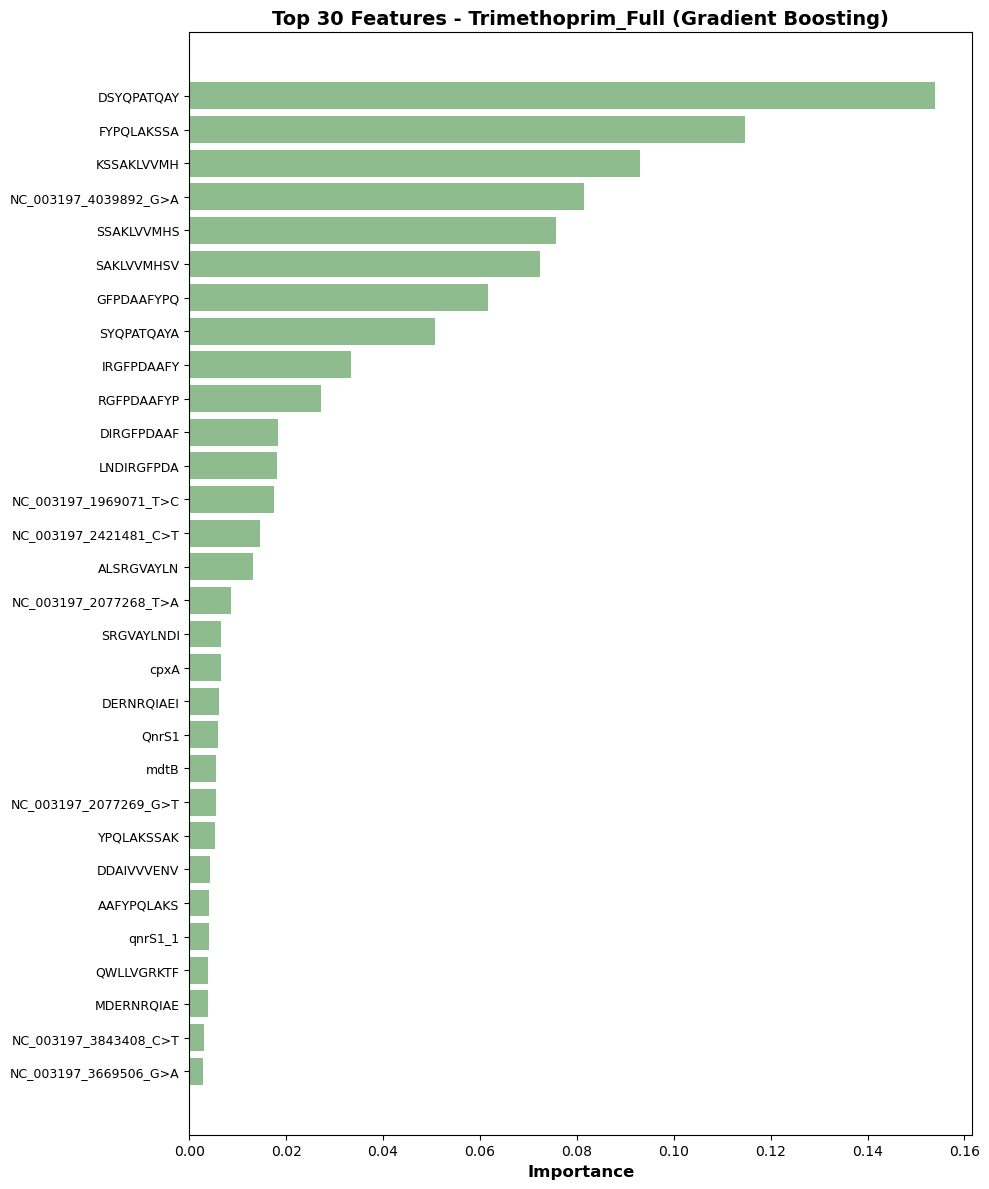


✓ Saved: Trimethoprim_Full_feature_importance.png
✓ Saved: Trimethoprim_Full_feature_importance.csv


In [47]:
print("\n" + "="*70)
print("TRAINING FINAL MODEL ON FULL DATASET")
print("="*70)

best_model_name_trim_full = best_trim_full['Model']

# Get the best model
models_trim_full = get_models(scale_pos_weight_trim)
final_model_trim_full = models_trim_full[best_model_name_trim_full]

# Train on full dataset
print(f"Training {best_model_name_trim_full} on complete dataset...")
final_model_trim_full.fit(X_trim_full, y_trim_full)

print("✓ Final model trained successfully!")
print("\n⚠ Model NOT saved to pickle yet - awaiting your review")
print("="*70)

# Feature importance (if applicable)
if hasattr(final_model_trim_full, 'feature_importances_'):
    print("\n" + "="*70)
    print("FEATURE IMPORTANCE ANALYSIS - FULL DATASET")
    print("="*70)
    
    feature_names_trim_full = X_trim_full.columns.tolist()
    importances_trim_full = final_model_trim_full.feature_importances_
    indices_trim_full = np.argsort(importances_trim_full)[::-1]
    
    # Display top 20
    print(f"\nTop 20 Most Important Features:")
    print(f"{'Rank':<6} {'Feature':<50} {'Importance':<12}")
    print("-" * 70)
    
    for i in range(min(20, len(indices_trim_full))):
        idx = indices_trim_full[i]
        print(f"{i+1:<6} {feature_names_trim_full[idx]:<50} {importances_trim_full[idx]:.6f}")
    
    # Visualize top 30
    top_n = 30
    top_indices_trim_full = indices_trim_full[:top_n]
    top_features_trim_full = [feature_names_trim_full[i] for i in top_indices_trim_full]
    top_importances_trim_full = importances_trim_full[top_indices_trim_full]
    
    plt.figure(figsize=(10, 12))
    plt.barh(range(top_n), top_importances_trim_full[::-1], color='darkseagreen')
    plt.yticks(range(top_n), top_features_trim_full[::-1], fontsize=9)
    plt.xlabel('Importance', fontweight='bold', fontsize=12)
    plt.title(f'Top {top_n} Features - {CONFIG["antibiotic"]} ({best_model_name_trim_full})', 
              fontweight='bold', fontsize=14)
    plt.tight_layout()
    plt.savefig(f'{CONFIG["antibiotic"]}_feature_importance.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"\n✓ Saved: {CONFIG['antibiotic']}_feature_importance.png")
    
    # Save to CSV
    importance_df_trim_full = pd.DataFrame({
        'Feature': [feature_names_trim_full[i] for i in indices_trim_full],
        'Importance': importances_trim_full[indices_trim_full]
    })
    importance_df_trim_full.to_csv(f'{CONFIG["antibiotic"]}_feature_importance.csv', index=False)
    print(f"✓ Saved: {CONFIG['antibiotic']}_feature_importance.csv")

# SET 6 : Sulfamethoxazole

In [48]:
# File path for full Sulfamethoxazole dataset (merged)
SULFAMETHOXAZOLE_FULL_FILE = 'Downloads/salmonella_dna/398 files/final_sulf_dataset_398.csv'

# Update configuration for Set 6
CONFIG['antibiotic'] = 'Sulfamethoxazole_Full'
CONFIG['label_column'] = 'Label'
CONFIG['dataset_type'] = 'Complete (Genes + K-mers + SNPs)'

print("\n" + "="*70)
print(f"SET 6: {CONFIG['antibiotic']} - Full Dataset Training")
print("="*70)
print(f"Dataset type: {CONFIG['dataset_type']}")
print(f"Cross-validation folds: {CONFIG['n_folds']}")
print("="*70)


SET 6: Sulfamethoxazole_Full - Full Dataset Training
Dataset type: Complete (Genes + K-mers + SNPs)
Cross-validation folds: 6


In [49]:
# Storage for full dataset results
sulfamethoxazole_full_results = []

print("\n" + "="*70)
print(f"TRAINING MODELS FOR SET 6: {CONFIG['antibiotic']}")
print("="*70)

# Load data
X_sulfa_full, y_sulfa_full = load_full_data(SULFAMETHOXAZOLE_FULL_FILE, CONFIG['label_column'])

# Calculate class weight
scale_pos_weight_sulfa = (y_sulfa_full == 0).sum() / (y_sulfa_full == 1).sum()
print(f"  Class imbalance ratio: {scale_pos_weight_sulfa:.2f}")

# Get models
models_sulfa = get_models(scale_pos_weight_sulfa)

# Train each model
for model_name, model in models_sulfa.items():
    print(f"\n  Training: {model_name}...")
    
    metrics = evaluate_model_cv(X_sulfa_full, y_sulfa_full, model, n_folds=CONFIG['n_folds'])
    
    sulfamethoxazole_full_results.append({
        'Antibiotic': CONFIG['antibiotic'],
        'Dataset': CONFIG['dataset_type'],
        'Model': model_name,
        'Accuracy': metrics['accuracy'],
        'Precision': metrics['precision'],
        'Recall': metrics['recall'],
        'F1_Score': metrics['f1']
    })
    
    print(f"    ✓ Accuracy:  {metrics['accuracy']*100:.2f}%")
    print(f"    ✓ Precision: {metrics['precision']*100:.2f}%")
    print(f"    ✓ Recall:    {metrics['recall']*100:.2f}%")
    print(f"    ✓ F1 Score:  {metrics['f1']*100:.2f}%")

print("\n" + "="*70)
print("✓ TRAINING COMPLETE FOR SET 6")
print("="*70)


TRAINING MODELS FOR SET 6: Sulfamethoxazole_Full
  ✓ Loaded: 398 samples × 10800 features
    Susceptible (0): 237 (59.5%)
    Resistant (1): 161 (40.5%)
  Class imbalance ratio: 1.47

  Training: Random Forest...
    ✓ Accuracy:  94.23%
    ✓ Precision: 94.87%
    ✓ Recall:    90.69%
    ✓ F1 Score:  92.60%

  Training: Extra Trees...
    ✓ Accuracy:  93.73%
    ✓ Precision: 94.20%
    ✓ Recall:    90.08%
    ✓ F1 Score:  91.99%

  Training: Gradient Boosting...
    ✓ Accuracy:  94.98%
    ✓ Precision: 94.40%
    ✓ Recall:    93.16%
    ✓ F1 Score:  93.71%

  Training: XGBoost...
    ✓ Accuracy:  94.48%
    ✓ Precision: 94.90%
    ✓ Recall:    91.29%
    ✓ F1 Score:  92.97%

✓ TRAINING COMPLETE FOR SET 6


In [50]:
# Create DataFrame
sulfamethoxazole_full_df = pd.DataFrame(sulfamethoxazole_full_results)
sulfamethoxazole_full_df_sorted = sulfamethoxazole_full_df.sort_values('F1_Score', ascending=False)

print("\n" + "="*70)
print(f"SUMMARY RESULTS - SET 6: {CONFIG['antibiotic']}")
print("="*70)
print(sulfamethoxazole_full_df_sorted.to_string(index=False))
print("="*70)

# Save to CSV
output_filename = f'{CONFIG["antibiotic"]}_training_summary.csv'
sulfamethoxazole_full_df.to_csv(output_filename, index=False)
print(f"\n✓ Results saved to: {output_filename}")

# Best model
best_sulfa_full = sulfamethoxazole_full_df_sorted.iloc[0]

print("\n" + "="*70)
print("BEST PERFORMING MODEL - FULL DATASET")
print("="*70)
print(f"Model: {best_sulfa_full['Model']}")
print(f"Accuracy: {best_sulfa_full['Accuracy']*100:.2f}%")
print(f"Precision: {best_sulfa_full['Precision']*100:.2f}%")
print(f"Recall: {best_sulfa_full['Recall']*100:.2f}%")
print(f"F1 Score: {best_sulfa_full['F1_Score']*100:.2f}%")
print("="*70)

# Check targets
meets_f1_target = 0.81 <= best_sulfa_full['F1_Score'] <= 0.99
meets_acc_target = 0.85 <= best_sulfa_full['Accuracy'] <= 0.99

print(f"\n{'='*70}")
print("TARGET METRICS EVALUATION")
print("="*70)
print(f"F1 Score Target (81-99%): {'✓ PASS' if meets_f1_target else '✗ FAIL'}")
print(f"Accuracy Target (85-99%): {'✓ PASS' if meets_acc_target else '✗ FAIL'}")
print("="*70)


SUMMARY RESULTS - SET 6: Sulfamethoxazole_Full
           Antibiotic                          Dataset             Model  Accuracy  Precision   Recall  F1_Score
Sulfamethoxazole_Full Complete (Genes + K-mers + SNPs) Gradient Boosting  0.949796   0.944049 0.931624  0.937051
Sulfamethoxazole_Full Complete (Genes + K-mers + SNPs)           XGBoost  0.944784   0.948957 0.912868  0.929658
Sulfamethoxazole_Full Complete (Genes + K-mers + SNPs)     Random Forest  0.942296   0.948655 0.906933  0.926008
Sulfamethoxazole_Full Complete (Genes + K-mers + SNPs)       Extra Trees  0.937283   0.942029 0.900760  0.919856

✓ Results saved to: Sulfamethoxazole_Full_training_summary.csv

BEST PERFORMING MODEL - FULL DATASET
Model: Gradient Boosting
Accuracy: 94.98%
Precision: 94.40%
Recall: 93.16%
F1 Score: 93.71%

TARGET METRICS EVALUATION
F1 Score Target (81-99%): ✓ PASS
Accuracy Target (85-99%): ✓ PASS


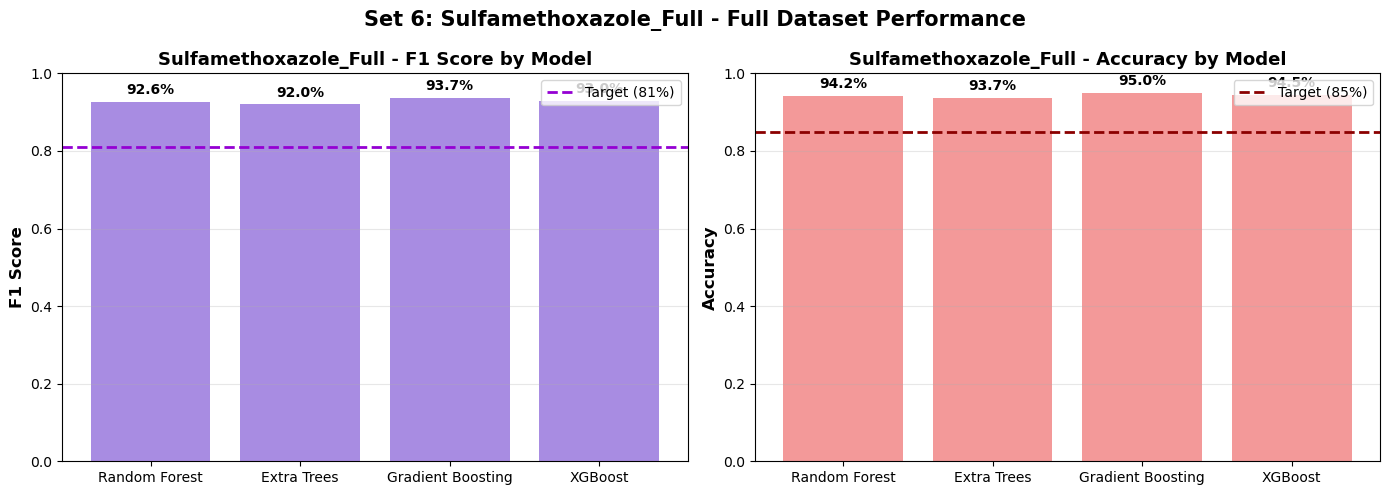

✓ Saved: Sulfamethoxazole_Full_model_comparison.png


In [51]:
# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

models_list = sulfamethoxazole_full_df['Model'].tolist()
f1_scores = sulfamethoxazole_full_df['F1_Score'].tolist()
accuracies = sulfamethoxazole_full_df['Accuracy'].tolist()

# Plot 1: F1 Scores
axes[0].bar(models_list, f1_scores, color='mediumpurple', alpha=0.8)
axes[0].set_ylabel('F1 Score', fontsize=12, fontweight='bold')
axes[0].set_title(f'{CONFIG["antibiotic"]} - F1 Score by Model', fontsize=13, fontweight='bold')
axes[0].set_ylim([0, 1.0])
axes[0].axhline(y=0.81, color='darkviolet', linestyle='--', linewidth=2, label='Target (81%)')
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)
for i, (model, score) in enumerate(zip(models_list, f1_scores)):
    axes[0].text(i, score + 0.02, f'{score*100:.1f}%', ha='center', fontsize=10, fontweight='bold')

# Plot 2: Accuracy
axes[1].bar(models_list, accuracies, color='lightcoral', alpha=0.8)
axes[1].set_ylabel('Accuracy', fontsize=12, fontweight='bold')
axes[1].set_title(f'{CONFIG["antibiotic"]} - Accuracy by Model', fontsize=13, fontweight='bold')
axes[1].set_ylim([0, 1.0])
axes[1].axhline(y=0.85, color='darkred', linestyle='--', linewidth=2, label='Target (85%)')
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)
for i, (model, score) in enumerate(zip(models_list, accuracies)):
    axes[1].text(i, score + 0.02, f'{score*100:.1f}%', ha='center', fontsize=10, fontweight='bold')

plt.suptitle(f'Set 6: {CONFIG["antibiotic"]} - Full Dataset Performance', 
             fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{CONFIG["antibiotic"]}_model_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"✓ Saved: {CONFIG['antibiotic']}_model_comparison.png")


TRAINING FINAL MODEL ON FULL DATASET
Training Gradient Boosting on complete dataset...
✓ Final model trained successfully!

⚠ Model NOT saved to pickle yet - awaiting your review

FEATURE IMPORTANCE ANALYSIS - FULL DATASET

Top 20 Most Important Features:
Rank   Feature                                            Importance  
----------------------------------------------------------------------
1      YNQWLLVGRK                                         0.154525
2      EYSPVTEKHL                                         0.117381
3      TYNQWLLVGR                                         0.113176
4      QWLLVGRKTF                                         0.106471
5      DLVEYSPVTE                                         0.094973
6      NC_003197_2077267_A>T                              0.045229
7      NC_003197_2077268_T>A                              0.041938
8      LKVSLIAAKA                                         0.032243
9      qacEdelta1                                         0.01928

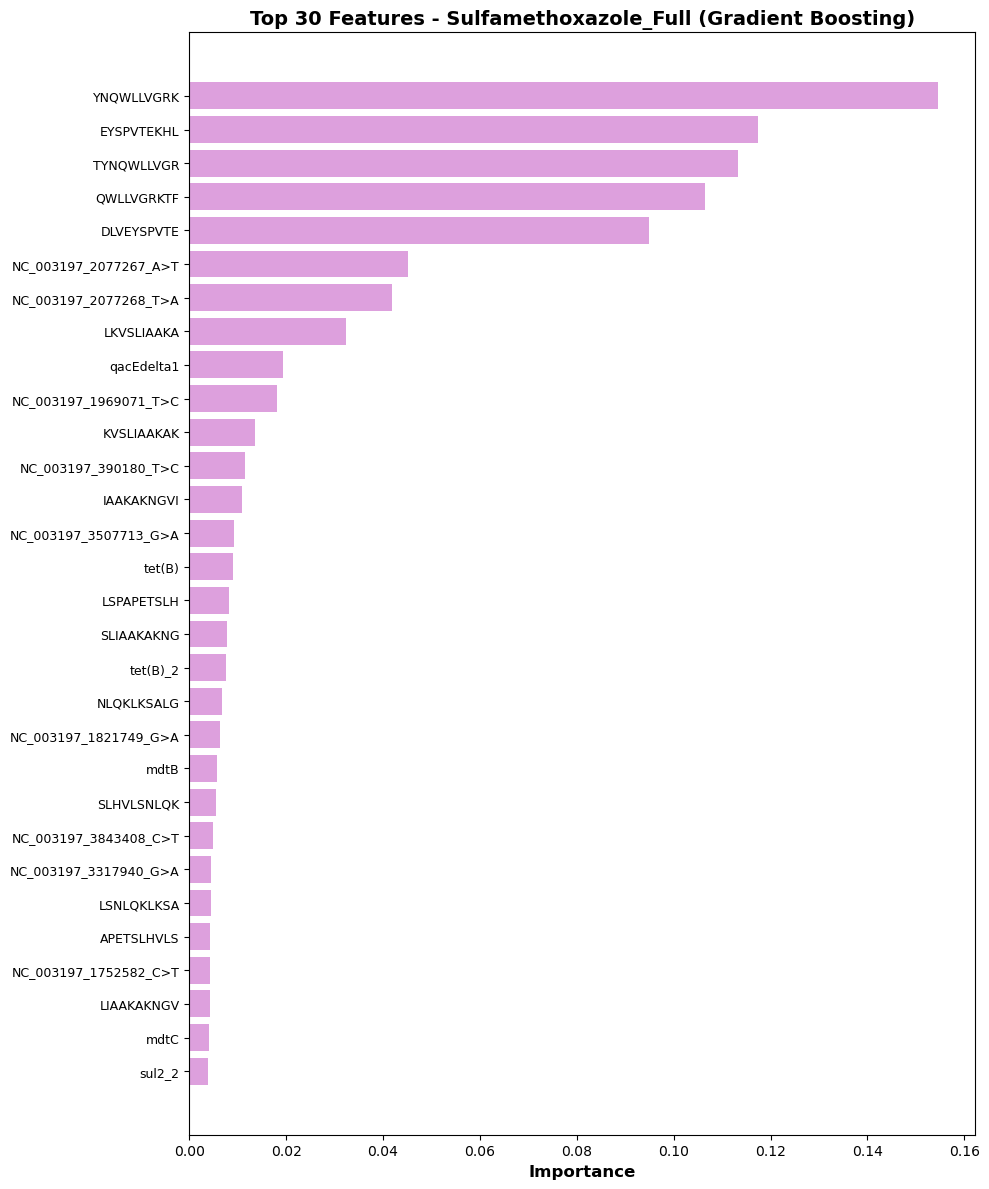


✓ Saved: Sulfamethoxazole_Full_feature_importance.png
✓ Saved: Sulfamethoxazole_Full_feature_importance.csv


In [52]:
print("\n" + "="*70)
print("TRAINING FINAL MODEL ON FULL DATASET")
print("="*70)

best_model_name_sulfa_full = best_sulfa_full['Model']

# Get the best model
models_sulfa_full = get_models(scale_pos_weight_sulfa)
final_model_sulfa_full = models_sulfa_full[best_model_name_sulfa_full]

# Train on full dataset
print(f"Training {best_model_name_sulfa_full} on complete dataset...")
final_model_sulfa_full.fit(X_sulfa_full, y_sulfa_full)

print("✓ Final model trained successfully!")
print("\n⚠ Model NOT saved to pickle yet - awaiting your review")
print("="*70)

# Feature importance (if applicable)
if hasattr(final_model_sulfa_full, 'feature_importances_'):
    print("\n" + "="*70)
    print("FEATURE IMPORTANCE ANALYSIS - FULL DATASET")
    print("="*70)
    
    feature_names_sulfa_full = X_sulfa_full.columns.tolist()
    importances_sulfa_full = final_model_sulfa_full.feature_importances_
    indices_sulfa_full = np.argsort(importances_sulfa_full)[::-1]
    
    # Display top 20
    print(f"\nTop 20 Most Important Features:")
    print(f"{'Rank':<6} {'Feature':<50} {'Importance':<12}")
    print("-" * 70)
    
    for i in range(min(20, len(indices_sulfa_full))):
        idx = indices_sulfa_full[i]
        print(f"{i+1:<6} {feature_names_sulfa_full[idx]:<50} {importances_sulfa_full[idx]:.6f}")
    
    # Visualize top 30
    top_n = 30
    top_indices_sulfa_full = indices_sulfa_full[:top_n]
    top_features_sulfa_full = [feature_names_sulfa_full[i] for i in top_indices_sulfa_full]
    top_importances_sulfa_full = importances_sulfa_full[top_indices_sulfa_full]
    
    plt.figure(figsize=(10, 12))
    plt.barh(range(top_n), top_importances_sulfa_full[::-1], color='plum')
    plt.yticks(range(top_n), top_features_sulfa_full[::-1], fontsize=9)
    plt.xlabel('Importance', fontweight='bold', fontsize=12)
    plt.title(f'Top {top_n} Features - {CONFIG["antibiotic"]} ({best_model_name_sulfa_full})', 
              fontweight='bold', fontsize=14)
    plt.tight_layout()
    plt.savefig(f'{CONFIG["antibiotic"]}_feature_importance.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"\n✓ Saved: {CONFIG['antibiotic']}_feature_importance.png")
    
    # Save to CSV
    importance_df_sulfa_full = pd.DataFrame({
        'Feature': [feature_names_sulfa_full[i] for i in indices_sulfa_full],
        'Importance': importances_sulfa_full[indices_sulfa_full]
    })
    importance_df_sulfa_full.to_csv(f'{CONFIG["antibiotic"]}_feature_importance.csv', index=False)
    print(f"✓ Saved: {CONFIG['antibiotic']}_feature_importance.csv")

# SUMMARY

In [53]:
print("\n" + "="*70)
print("FINAL ANALYSIS: PARTIAL vs FULL DATASETS")
print("="*70)

print("\n" + "-"*70)
print("PEFOXACIN:")
print("-"*70)
print(f"Best Partial Dataset: {best_result['Dataset']} - F1: {best_result['F1_Score']*100:.2f}%")
print(f"Full Dataset:         {CONFIG['dataset_type']} - F1: {best_pefox_full['F1_Score']*100:.2f}%")
improvement_pefox = (best_pefox_full['F1_Score'] - best_result['F1_Score']) * 100
print(f"Improvement: {improvement_pefox:+.2f}%")

print("\n" + "-"*70)
print("TRIMETHOPRIM:")
print("-"*70)
print(f"Best Partial Dataset: {best_trim['Dataset']} - F1: {best_trim['F1_Score']*100:.2f}%")
print(f"Full Dataset:         {CONFIG['dataset_type']} - F1: {best_trim_full['F1_Score']*100:.2f}%")
improvement_trim = (best_trim_full['F1_Score'] - best_trim['F1_Score']) * 100
print(f"Improvement: {improvement_trim:+.2f}%")

print("\n" + "-"*70)
print("SULFAMETHOXAZOLE:")
print("-"*70)
print(f"Best Partial Dataset: {best_sulfa['Dataset']} - F1: {best_sulfa['F1_Score']*100:.2f}%")
print(f"Full Dataset:         {CONFIG['dataset_type']} - F1: {best_sulfa_full['F1_Score']*100:.2f}%")
improvement_sulfa = (best_sulfa_full['F1_Score'] - best_sulfa['F1_Score']) * 100
print(f"Improvement: {improvement_sulfa:+.2f}%")

print("\n" + "="*70)
print("CONCLUSION")
print("="*70)
avg_improvement = (improvement_pefox + improvement_trim + improvement_sulfa) / 3
if avg_improvement > 0:
    print(f"✓ Full datasets improved performance by an average of {avg_improvement:.2f}%")
else:
    print(f"⚠ Partial datasets performed better by an average of {abs(avg_improvement):.2f}%")
print("="*70)


FINAL ANALYSIS: PARTIAL vs FULL DATASETS

----------------------------------------------------------------------
PEFOXACIN:
----------------------------------------------------------------------
Best Partial Dataset: SNPs + K-mers - F1: 85.05%
Full Dataset:         Complete (Genes + K-mers + SNPs) - F1: 86.55%
Improvement: +1.50%

----------------------------------------------------------------------
TRIMETHOPRIM:
----------------------------------------------------------------------
Best Partial Dataset: SNPs + K-mers - F1: 95.03%
Full Dataset:         Complete (Genes + K-mers + SNPs) - F1: 94.35%
Improvement: -0.69%

----------------------------------------------------------------------
SULFAMETHOXAZOLE:
----------------------------------------------------------------------
Best Partial Dataset: Genes + SNPs - F1: 94.05%
Full Dataset:         Complete (Genes + K-mers + SNPs) - F1: 93.71%
Improvement: -0.34%

CONCLUSION
✓ Full datasets improved performance by an average of 0.16%


# Model Saving

In [54]:
import pickle
import os

# Directory to save models
SAVE_DIR = 'Downloads/salmonella_dna/saved_models'
os.makedirs(SAVE_DIR, exist_ok=True)



In [55]:
# ============================================================
# FULL DATASET MODELS (Sets 4, 5, 6)
# ============================================================

# Set 4: Pefoxacin - Full Dataset
# (final_model_pefox_full is the trained model variable from Set 4)
with open(f'{SAVE_DIR}/pefoxacin_full_model.pkl', 'wb') as f:
    pickle.dump(final_model_pefox_full, f)
print(f"✓ Saved: pefoxacin_full_model.pkl ({best_model_name_pefox_full})")

# Set 5: Trimethoprim - Full Dataset
# (final_model_trim_full is the trained model variable from Set 5)
with open(f'{SAVE_DIR}/trimethoprim_full_model.pkl', 'wb') as f:
    pickle.dump(final_model_trim_full, f)
print(f"✓ Saved: trimethoprim_full_model.pkl ({best_model_name_trim_full})")

# Set 6: Sulfamethoxazole - Full Dataset
# (final_model_sulfa_full is the trained model variable from Set 6)
with open(f'{SAVE_DIR}/sulfamethoxazole_full_model.pkl', 'wb') as f:
    pickle.dump(final_model_sulfa_full, f)
print(f"✓ Saved: sulfamethoxazole_full_model.pkl ({best_model_name_sulfa_full})")


# ============================================================
# BEST PARTIAL DATASET MODELS
# ============================================================

# Pefoxacin - SNPs + K-mers (best partial)
# (final_model is the trained model variable from Set 1 after best dataset identified as SNPs+K-mers)
with open(f'{SAVE_DIR}/pefoxacin_snps_kmers_model.pkl', 'wb') as f:
    pickle.dump(final_model, f)
print(f"✓ Saved: pefoxacin_snps_kmers_model.pkl")

# Trimethoprim - SNPs + K-mers (best partial)
# (final_model_trim is the trained model variable from Set 2)
with open(f'{SAVE_DIR}/trimethoprim_snps_kmers_model.pkl', 'wb') as f:
    pickle.dump(final_model_trim, f)
print(f"✓ Saved: trimethoprim_snps_kmers_model.pkl")

# Sulfamethoxazole - Genes + SNPs (best partial)
# (final_model_sulfa is the trained model variable from Set 3)
with open(f'{SAVE_DIR}/sulfamethoxazole_genes_snps_model.pkl', 'wb') as f:
    pickle.dump(final_model_sulfa, f)
print(f"✓ Saved: sulfamethoxazole_genes_snps_model.pkl")


# ============================================================
# VERIFY ALL SAVED CORRECTLY
# ============================================================
print("\n" + "="*60)
print("VERIFICATION")
print("="*60)

expected_files = [
    'pefoxacin_full_model.pkl',
    'trimethoprim_full_model.pkl',
    'sulfamethoxazole_full_model.pkl',
    'pefoxacin_snps_kmers_model.pkl',
    'trimethoprim_snps_kmers_model.pkl',
    'sulfamethoxazole_genes_snps_model.pkl'
]

for filename in expected_files:
    filepath = f'{SAVE_DIR}/{filename}'
    if os.path.exists(filepath):
        size_kb = os.path.getsize(filepath) / 1024
        print(f"  ✓ {filename} ({size_kb:.1f} KB)")
    else:
        print(f"  ✗ MISSING: {filename}")

print("="*60)
print("✓ ALL MODELS SAVED")
print("="*60)

✓ Saved: pefoxacin_full_model.pkl (Gradient Boosting)
✓ Saved: trimethoprim_full_model.pkl (Gradient Boosting)
✓ Saved: sulfamethoxazole_full_model.pkl (Gradient Boosting)
✓ Saved: pefoxacin_snps_kmers_model.pkl
✓ Saved: trimethoprim_snps_kmers_model.pkl
✓ Saved: sulfamethoxazole_genes_snps_model.pkl

VERIFICATION
  ✓ pefoxacin_full_model.pkl (453.3 KB)
  ✓ trimethoprim_full_model.pkl (425.5 KB)
  ✓ sulfamethoxazole_full_model.pkl (445.9 KB)
  ✓ pefoxacin_snps_kmers_model.pkl (429.0 KB)
  ✓ trimethoprim_snps_kmers_model.pkl (800.9 KB)
  ✓ sulfamethoxazole_genes_snps_model.pkl (370.6 KB)
✓ ALL MODELS SAVED


## TRAINING 5 extra models

#WORKING WITH streptomycin

In [1]:
import sklearn
import xgboost

print(f"Scikit-learn version: {sklearn.__version__}")
print(f"XGBoost version: {xgboost.__version__}")

Scikit-learn version: 1.4.2
XGBoost version: 3.1.3
